<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_FederatedDPGradientVariance_Thien2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adaptive differential privacy for quantum federated learning (ADP-QFL): Phan et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Duc-Thien Phan, Minh-Duong Nguyen, Quoc-Viet Pham and Huilong Pi,
> "Enhancing Gradient Variance and Differential Privacy in Quantum Federated Learning",
> arXiv:2509.05377v1 [quant-ph], 4 Sep 2025 (preprint; also TechRxiv, DOI [10.36227/techrxiv.175756490.02861176/v1](https://doi.org/10.36227/techrxiv.175756490.02861176/v1)).

(The first author is Duc-Thien Phan; the project's file name uses the form "Thien2025" taken from the bibliography.)

**What this notebook does.** The paper proposes ADP-QFL: 100 clients each train an 8-qubit quantum convolutional neural network (QCNN, 64 trainable circuit parameters) on a
private non-IID share of MNIST or CIFAR-10; a server averages the clients' models. To protect every client's data (client-level differential privacy), each client
(i) computes a meta-learning update from a support and a query set, (ii) replaces its update by a sparse *estimate* within an error bound and only takes part in the
aggregation if it is not an outlier, (iii) clips the update and adds Gaussian noise whose variance decays over the rounds, `sigma_t^2 = sigma_0^2 / (1 + alpha t)`.
The paper argues that such noise also counteracts the vanishing gradient *variance* of quantum circuits (barren plateaus). The notebook downloads both public data sets, builds
the 8-qubit QCNN as a PennyLane circuit (drawn and asserted equal to the fast simulator that trains it), runs ADP-QFL and its comparison methods in a faithful but scaled-down
federation, redraws the paper's Fig. 1 (gradient variance versus qubits and layers), Fig. 5 (noise levels), Fig. 6 (clients per round), Fig. 7 / Table VI (ADP-QFL versus QFL without
estimation versus classical FL with DP) and Table IV (accuracy), adds a **privacy accountant** (what epsilon do these noise levels actually give?), and ends with a verdict per claim.

**How to run it.** Open it in Google Colab (CPU runtime is enough) and choose *Runtime -> Run all*. `FAST_MODE = True` (the default in the configuration cell) runs a tiny federation in a few minutes;
`FAST_MODE = False` runs the larger budgets documented in the configuration cell (about 30 to 40 minutes on an 8-core laptop CPU). No quantum hardware, no IBM token and no
Hugging Face token are needed (both data sets are public); if a mirror ever becomes gated, store your own token as the Colab secret `HF_TOKEN` (or the environment variable `HF_TOKEN`) - it is only read from there and never printed.

**What you get at the end.** Accuracy curves for every method and noise level, the paper-versus-notebook table with a verdict per claim, the drawn 8-qubit circuit, real-data
visualisations of both data sets, privacy-accountant tables, and a critical reading of what the evidence supports.

# The paper in one page

**Problem.** Quantum federated learning (QFL) trains quantum neural networks (QNNs) on many clients without pooling their data, but (1) the QNN loss landscape has vanishing gradient *variance*
(barren plateaus: variance of the gradient shrinks exponentially with the number of qubits), so training gets stuck in sharp minima and the model updates become very predictable,
which helps an adversary who observes them; (2) the model transmitted to the server leaks information about the client's data; (3) quantum hardware noise perturbs training.

**Method (Section IV, Algorithm 1, Eqs. 3-7).** *ADP-QFL*. Server: initialise global model, noise variance, estimation error `b` and regularisation `lambda`; every round receive the perturbed local models and average them.
Client: start from the global model; draw a support set and a query set; compute an adapted model `theta~ = theta - eta * grad L(theta; support)`, then a second-order meta update
`phi = theta - beta (I - eta * Hessian L(theta~; support)) (grad L(theta~; query) + G_t)` with Gaussian noise `G_t` (Eq. 3-4); find a sparse estimate `phi^` with `||phi^ - phi|| <= b * lambda` (Eq. 7, inspired by RANSAC)
and send it only if it passes the consensus test; the noise variance decays as `sigma_t^2 = sigma_0^2 / (1 + alpha t)` (larger noise early, smaller late). Lemma 1 gives the Gaussian variance for `(epsilon, delta)` user-level DP:
`sigma^2 = 8 T (2L + b)^2 log(1/delta) / (K^2 epsilon^2)`.

**Model.** A quantum convolutional neural network on **8 qubits**: three pairs of quantum convolution and pooling layers, a quantum fully connected layer and a measurement layer, **64 trainable parameters** in total
(Section VI-A.2). The paper does not say how an image is turned into the 8-qubit input.

**Data and federation (Table II, Table III, Section VI).** MNIST (60,000 train / 10,000 test, 10 classes) and CIFAR-10 (50,000 / 10,000, 10 classes); **100 clients**, **800 rounds**, 10 % / 20 % / 50 % of the clients per round,
**1 local epoch**, batch size **10**, **Adam, learning rate 0.005**, **MSE loss**, label-skew **non-IID** partition ("each client holds data samples from a limited subset of classes").

**Claims that can be checked.**
* Table IV (after 800 rounds, 10 % participation): accuracy MNIST ADP-QFL **98.47**, FedAvg 98.16, FedBN 97.87, pFedMe 98.19, FedRep 98.44, FedQNN 92.05; CIFAR-10 ADP-QFL **83.85**, FedAvg 56.91, FedBN 85.61, pFedMe 57.51, FedRep 85.68, FedQNN 76.40
  (times 1356 s / 9322 s; paired t-tests in Table V).
* Fig. 5: ADP-QFL stays above **97.57 %** on MNIST (and reaches about 83.96 % on CIFAR-10) for the "noise levels" 0.000423, 0.001, 0.1, 0.5, 0.9 without tuning.
* Fig. 6: accuracy is stable over 10 / 20 / 50 % participation on MNIST; on CIFAR-10 it rises 82.78 -> 82.98 -> 83.85 %.
* Table VI / Fig. 7 (epsilon = 1, delta = 1e-5): test accuracy at rounds 100 / 300 / 600 / 800: ADP-QFL 0.83 / 0.91 / 0.94 / 0.98, QFL without estimation 0.78 / 0.85 / 0.89 / 0.90, classical FL with DP 0.72 / 0.80 / 0.84 / 0.85.
* Fig. 1 and Theorem 1 / Corollaries 1-3: gradient variance decays exponentially with the number of qubits (and saturates with depth, the 2-design limit); adding noise increases the effective gradient variance and helps to avoid sharp minima.
* Communication saving by sparse model estimation (no number given).

**Not reproducible as stated.** The comparison methods FedBN, pFedMe, FedRep and FedQNN (personalised methods, evaluated per client; not specified in enough detail), wall-clock times on a different machine, the statistical tests of Table V
(no repeated runs described), the claimed mitigation of *intermediate quantum device noise* (no noise experiment is reported in Section VI), and the CIFAR-10 accuracy of 83.85 % with an 8-qubit, 64-parameter circuit (a classical feature extractor of unknown size must carry most of the work).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data sets | MNIST 60,000 / 10,000 and CIFAR-10 50,000 / 10,000 | The same public data (Hugging Face `ylecun/mnist`, `uoft-cs/cifar10`; torchvision as fallback). MNIST: the full training file is the pool, the first `FINAL_TEST` of a seeded random shuffle of the 10,000 test images are used. CIFAR-10: a seeded random pool of 12,000 of the 50,000 training images and 2,000 test images (a CPU simulation of 100 clients on all 50,000 images is not possible) |
| Clients | 100 clients, whole training set shared out (600 MNIST images each) | 100 clients with only `N_PER_CLIENT` images each (30 in `FAST_MODE`, 50 in the full run): 5,000 of the 60,000 MNIST images are used. Every image is used once |
| Non-IID partition | "each client holds data samples from a limited subset of classes (label-distribution skew)" | Dirichlet label skew, concentration `DIRICHLET_BETA = 0.5`; every client gets exactly `N_PER_CLIENT` images (`# CHOICE`) |
| Rounds | 800 | `ROUNDS_MNIST` = 10 (fast) / 120 (full), `ROUNDS_CIFAR` = 4 / 50. About 5 % of the paper's number of local gradient steps per client (the paper: 800 rounds x 60 steps) |
| Participation | 10 %, 20 %, 50 % | the same fractions (10, 20, 50 clients); 10 % is the main setting (Table IV) |
| Local training | 1 epoch, batch 10, Adam lr 0.005, MSE | the same (a fresh Adam state each round, as a real client would have) |
| Image -> 8 qubits | not stated | a **trainable classical encoder** maps the image to 8 angles, `angle = pi * tanh(.)`, one RY per qubit. MNIST: 2x2 average pooling (196 features) -> `Linear(196, 8)`; CIFAR-10: two small convolutions + `Linear(256, 8)` (`# CHOICE`; the encoder is trained and aggregated together with the circuit) |
| QCNN | 8 qubits, 3 conv-pool pairs, quantum FC layer, measurement, 64 parameters | blocks of the Qiskit QCNN tutorial (3 parameters each): layer 1 = 8 convolution blocks on a ring + 4 pooling blocks, layer 2 = 4 + 2, layer 3 = 2 + 1, i.e. 21 blocks x 3 = 63, plus one final RY = **64 parameters** (`# CHOICE`). All 8 qubits are measured in Z (the pooled-away qubits keep their last state), followed by a classical read-out `Linear(8, 10)` instead of a "quantum fully connected layer" (`# CHOICE`) |
| Meta update | second-order, Eq. 3-4 | support/query meta-update with the **first-order** gradient `grad L(theta~; query)`; the `eta * Hessian` correction is dropped to save a factor ~2 of CPU time. A check cell compares it with the exact second-order meta-gradient (`# CHOICE`), `META_ETA = 0.01`; each mini-batch of 10 is split into support 5 / query 5 |
| Where the noise enters | Eq. 4 adds `G_t` to the query gradient; Section IV-C adds it to the transmitted parameters | to the **transmitted update** (client-level DP; the clipped update is what a server sees), clip norm `CLIP_C = 1`, noise std `sigma_t = z * CLIP_C / sqrt(1 + alpha t)`, `alpha = 0.01` (`# CHOICE`) |
| "Noise level" / privacy budget | legend of Fig. 5: 0.000423 ... 0.9, called epsilon and noise | the noise multiplier `z`; Lemma 1 would give astronomically large noise for such epsilons, so `z` is used directly; the privacy accountant cell computes the real epsilon. The main comparison runs use `Z_MAIN = 0.01`, an extra level between the paper's 0.001 and 0.1, because at 0.1 the QCNN no longer trains within the shortened budget (`# CHOICE`) |
| Estimation (Eq. 7) | sparse estimate `phi^` with `||phi^ - phi|| <= b * lambda`; only clients whose estimate passes a threshold take part | sparsest estimate with relative error `b * lambda = EST_REL_ERR = 0.3` (largest-magnitude entries kept); consensus filter: a client is dropped if `||update||` exceeds `SEL_KAPPA = 2` times the median of the round (`# CHOICE`); noise is added to the transmitted coordinates only |
| Compared methods | FedAvg, FedBN, pFedMe, FedRep, FedQNN (Table IV); QFL without estimation, classical FL with DP (Fig. 7) | **FedAvg-QCNN** without DP, **DP-FedAvg-QCNN** (clipping + fixed noise), **QFL without estimation** (= ADP-QFL minus sparse estimation / consensus), **classical FL with DP** and a classical FedAvg (same encoder, the circuit replaced by a classical 8x8 tanh layer with the same 64 parameters), several seeds for the cheap classical runs. FedBN, pFedMe, FedRep, FedQNN are **not re-implemented** |
| Simulator | not stated | exact state-vector simulation; the stacked simulator that trains all clients at once is asserted equal (values and gradients, 1e-10) to a PennyLane QNode, which is drawn |
| Gradient-variance study (Fig. 1) | layered circuits, 2 to 10 qubits, up to 200 layers (ansatz not stated) | RY + CZ layered circuit, local and global cost, exact parameter-shift gradients of the first parameter over random initialisations (`# CHOICE`) |
| Seeds | not stated | `SEED = 42`; two federation seeds (initialisation, client sampling, noise) for the headline quantum runs, three for the classical runs, one for the noise / participation sweeps |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): torch 2.14.1, pennylane 0.45.1, scikit-learn 1.9, pandas 3.0, matplotlib 3.11.
# Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and torchvision; only PennyLane has to be added.
# The pip line runs on Colab (or wherever PennyLane / torch is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False     # True: tiny federation, a few minutes, accuracies are near chance (checks that the code runs).
                     # False: the larger budgets below (100 clients x 50 images, 120 / 50 rounds, 5 + 1 noise levels, 3 participation rates, 2 seeds, ...);
                     #        about 30 to 40 minutes on an 8-core laptop CPU (28 min in the committed run) (the committed outputs come from this setting if the header says FAST_MODE=False).
SEED = 42            # CHOICE: seed of the data subsample, the partition, the initial weights, the client sampling and the noise (the paper gives none)

# --- paper values (Section VI-A, Table II, Fig. 5-6) ---
N_QUBITS    = 8              # 8-qubit QCNN
N_CLIENTS   = 100            # total number of clients
LOCAL_EPOCHS = 1             # local epochs per round
BATCH       = 10             # batch size
LR          = 0.005          # Adam learning rate (no weight decay), MSE loss
NOISE_LEVELS = [0.000423, 0.001, 0.1, 0.5, 0.9]   # the five "noise levels" of Fig. 5
FRAC_MAIN   = 0.1            # 10 % of the clients per round (Table IV)
FRACS       = [0.1, 0.2, 0.5]
PAPER_ROUNDS = 800
DELTA       = 1e-5           # delta of Table VI

# --- choices the paper leaves open ---
DIRICHLET_BETA = 0.5         # CHOICE: strength of the label skew (smaller = more skewed)
META_ETA    = 0.01           # CHOICE: inner step size eta of the meta update (Eq. 3)
CLIP_C      = 1.0            # CHOICE: clip norm of a client's update (sensitivity of the Gaussian mechanism)
ALPHA_DECAY = 0.01           # CHOICE: decay rate alpha of sigma_t^2 = sigma_0^2 / (1 + alpha t)
Z_MAIN      = 0.01           # CHOICE: noise multiplier of the main comparison runs (between the paper's 0.001 and 0.1: visible, but training still works)
EST_REL_ERR = 0.3            # CHOICE: relative error b*lambda of the sparse estimate (Eq. 7)
SEL_KAPPA   = 2.0            # CHOICE: a client is dropped if ||update|| > SEL_KAPPA * median of the round

if FAST_MODE:
    N_PER_CLIENT = 30                  # 3 local steps per round
    ROUNDS_MNIST, ROUNDS_CIFAR = 10, 4
    MAIN_SEEDS = [0]
    NOISE_RUN = [0.001, Z_MAIN, 0.9]   # noise levels actually run
    FRACS_RUN = [0.1, 0.2]
    EVAL_TEST, FINAL_TEST, FINAL_TRAIN = 300, 500, 300
    CLASSICAL_SEEDS = [0]
    GV_QUBITS, GV_DEPTHS, GV_SAMPLES = [2, 4, 6, 8], [1, 2, 5, 10, 20], 100
else:
    N_PER_CLIENT = 50                  # 5 local steps per round
    ROUNDS_MNIST, ROUNDS_CIFAR = 120, 50
    MAIN_SEEDS = [0, 1]                # two federation seeds for the headline quantum runs (ADP-QFL, QFL without estimation, FedAvg-QCNN, DP-FedAvg-QCNN)
    NOISE_RUN = sorted(set(NOISE_LEVELS + [Z_MAIN]))
    FRACS_RUN = FRACS
    EVAL_TEST, FINAL_TEST, FINAL_TRAIN = 300, 1500, 500
    CLASSICAL_SEEDS = [0, 1, 2]
    GV_QUBITS, GV_DEPTHS, GV_SAMPLES = [2, 4, 6, 8, 10], [1, 2, 5, 10, 20, 50, 100], 150

CFG = {"mnist": dict(pool=60000, n_test=10000), "cifar": dict(pool=12000, n_test=2000)}   # images read from the official splits (CIFAR-10: random pool, see the table above)
DATA_DIR  = "qc155_data"     # downloads are cached here (the large parquet files are deleted after reading; only small .npz subsets stay)
IBM_TOKEN = ""               # unused: the paper evaluates ideal simulations only
print("FAST_MODE =", FAST_MODE, "| clients:", N_CLIENTS, "x", N_PER_CLIENT, "images | rounds (MNIST, CIFAR-10):", ROUNDS_MNIST, ROUNDS_CIFAR,
      "| noise levels run:", NOISE_RUN, "| participation run:", FRACS_RUN)

FAST_MODE = False | clients: 100 x 50 images | rounds (MNIST, CIFAR-10): 120 50 | noise levels run: [0.000423, 0.001, 0.01, 0.1, 0.5, 0.9] | participation run: [0.1, 0.2, 0.5]


In [3]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

import torch
import pennylane as qml

torch.set_num_threads(1)           # many tiny tensors: one thread is fastest and is kind to a shared CPU
np.random.seed(SEED); torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. The two public data sets

**MNIST** (LeCun et al.): 70,000 grey-scale 28 x 28 images of handwritten digits, 10 classes (0 to 9); the official split has 60,000 training and 10,000 test images.
**CIFAR-10** (Krizhevsky): 60,000 colour 32 x 32 images in 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck); 50,000 training and 10,000 test images.
Both are read from the official parquet files on the Hugging Face hub (`ylecun/mnist`, `uoft-cs/cifar10`); the large CIFAR-10 file is deleted again after the images have been extracted.

Everything below is fitted on **training images only**: the feature scaling (one mean / standard deviation for MNIST, one per colour channel for CIFAR-10) uses the clients' training images; the test images are only transformed.
The 100 clients get label-skewed shares: client *i* draws its class proportions from a Dirichlet distribution and receives exactly `N_PER_CLIENT` images.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed if a mirror becomes gated)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

import io
from PIL import Image
MNIST_CLASSES = [str(d) for d in range(10)]
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
HF_SPEC = {"mnist": ("ylecun/mnist", "mnist/{s}-00000-of-00001.parquet", "image"),
           "cifar": ("uoft-cs/cifar10", "plain_text/{s}-00000-of-00001.parquet", "img")}

def _decode(cells, idx):
    return np.stack([np.array(Image.open(io.BytesIO(cells[int(i)]["bytes"]))) for i in idx]).astype(np.uint8)

def _hf_split(name, split):
    from huggingface_hub import hf_hub_download
    repo, pattern, col = HF_SPEC[name]
    path = hf_hub_download(repo, pattern.format(s=split), repo_type="dataset", token=HF_TOKEN, cache_dir=os.path.join(DATA_DIR, "hf"))
    df = pd.read_parquet(path)
    return df[col].tolist(), df["label"].to_numpy(), path

def _tv_split(name, split):
    import torchvision
    cls = torchvision.datasets.MNIST if name == "mnist" else torchvision.datasets.CIFAR10
    ds = cls(os.path.join(DATA_DIR, "tv"), train=(split == "train"), download=True)
    data = ds.data.numpy() if hasattr(ds.data, "numpy") else np.asarray(ds.data)
    return data.astype(np.uint8), np.asarray(ds.targets)

def load_images(name, n_train_pool, n_test):
    """Real images of the official train / test split (random subset of n_train_pool / n_test images, fixed by SEED); cached as a small .npz in DATA_DIR."""
    cache = os.path.join(DATA_DIR, f"{name}_{n_train_pool}_{n_test}_seed{SEED}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["xtr"], z["ytr"], z["xte"], z["yte"], "cache"
    rng = np.random.default_rng(SEED)
    out = {}
    try:
        src = "Hugging Face " + HF_SPEC[name][0]
        for split, n in (("train", n_train_pool), ("test", n_test)):
            cells, y, path = _hf_split(name, split)
            idx = np.sort(rng.choice(len(y), size=min(n, len(y)), replace=False))
            out[split] = (_decode(cells, idx), y[idx])
            if os.path.getsize(path) > 50e6:
                os.remove(path); print("  deleted the large downloaded file", os.path.basename(path), "after reading it")      # keep the cache folder small
    except Exception as e:
        print(f"[{name}] Hugging Face mirror failed ({type(e).__name__}: {str(e)[:80]}); using torchvision")
        src = "torchvision"
        for split, n in (("train", n_train_pool), ("test", n_test)):
            data, y = _tv_split(name, split)
            idx = np.sort(rng.choice(len(y), size=min(n, len(y)), replace=False)); out[split] = (data[idx], y[idx])
    np.savez_compressed(cache, xtr=out["train"][0], ytr=out["train"][1], xte=out["test"][0], yte=out["test"][1])
    return out["train"][0], out["train"][1], out["test"][0], out["test"][1], src

def dirichlet_partition(y, n_clients, n_per, beta, rng):
    """Label-distribution skew: client i draws its class proportions from Dirichlet(beta) and receives exactly n_per images (no image is used twice)."""
    n_cls = int(y.max()) + 1
    pools = [list(rng.permutation(np.where(y == c)[0])) for c in range(n_cls)]
    props = rng.dirichlet([beta] * n_cls, size=n_clients)
    parts = []
    for i in range(n_clients):
        counts = rng.multinomial(n_per, props[i])
        for c in range(n_cls):                                        # a class pool can run dry: move the shortfall to the class with the most images left
            if counts[c] > len(pools[c]):
                short = counts[c] - len(pools[c]); counts[c] = len(pools[c])
                counts[int(np.argmax([len(p) for p in pools]))] += short
        idx = []
        for c in range(n_cls):
            idx += [pools[c].pop() for _ in range(counts[c])]
        parts.append(np.array(idx))
    return parts

def build_dataset(name):
    """Returns a dict with client tensors (n_clients, n_per, ...), the pooled raw training pool, and the test tensors; all scalers fitted on training images only."""
    ncfg = CFG[name]
    xtr, ytr, xte, yte, src = load_images(name, ncfg["pool"], ncfg["n_test"])
    rng = np.random.default_rng(SEED)
    parts = dirichlet_partition(ytr, N_CLIENTS, N_PER_CLIENT, DIRICHLET_BETA, rng)
    used = np.concatenate(parts)
    if name == "mnist":
        feat = lambda x: x.astype(np.float32).reshape(len(x), 14, 2, 14, 2).mean((2, 4)).reshape(len(x), -1) / 255.0         # 2x2 average pooling: 784 pixels -> 196 features
        Ftr, Fte = feat(xtr), feat(xte)
        mu, sd = Ftr[used].mean(), Ftr[used].std()                    # one scalar mean / std, fitted on the training images of the clients only
        norm = lambda F_: ((F_ - mu) / sd).astype(np.float32)
        names = [f"pool_{r}_{c}" for r in range(14) for c in range(14)]
    else:
        feat = lambda x: (x.astype(np.float32) / 255.0).transpose(0, 3, 1, 2)                                                 # (N, 3, 32, 32)
        Ftr, Fte = feat(xtr), feat(xte)
        mu = Ftr[used].mean((0, 2, 3), keepdims=True); sd = Ftr[used].std((0, 2, 3), keepdims=True)
        norm = lambda F_: ((F_ - mu) / sd).astype(np.float32)
        names = [f"{ch}_{r}_{c}" for ch in "RGB" for r in range(32) for c in range(32)]
    Xtr_n, Xte_n = norm(Ftr), norm(Fte)
    Xc = torch.tensor(np.stack([Xtr_n[p] for p in parts])); Yc = torch.tensor(np.stack([ytr[p] for p in parts]), dtype=torch.long)
    return dict(name=name, src=src, classes=MNIST_CLASSES if name == "mnist" else CIFAR_CLASSES, feat_names=names,
                raw_tr=xtr, y_tr=ytr, parts=parts, Xc=Xc, Yc=Yc, Xte=torch.tensor(Xte_n), Yte=torch.tensor(yte, dtype=torch.long),
                raw_te=xte, norm=norm, feat_tr=Ftr)

In [5]:
DATA = {}
for nm in ("mnist", "cifar"):
    t0 = time.time()
    DATA[nm] = build_dataset(nm)
    d = DATA[nm]
    print(f"{nm}: source = {d['src']} | client tensor {tuple(d['Xc'].shape)} | test tensor {tuple(d['Xte'].shape)} | {time.time()-t0:.0f}s")

mnist: source = cache | client tensor (100, 50, 196) | test tensor (10000, 196) | 5s


cifar: source = cache | client tensor (100, 50, 3, 32, 32) | test tensor (2000, 3, 32, 32) | 6s


## Dataset Exploration and Visualisation

Everything plotted here is real data: the number of images and features, the original labels, the class distributions of the pool, of the 100 clients and of the test images,
example images, the label skew of the clients, and the real training images projected on their first two principal components (PCA fitted on the clients' training images, raw coordinates first, then the same
coordinates rescaled to [0, pi] as angles would be for angle encoding), each point coloured by its ground-truth class. The labels are the original 10-class labels.

In [6]:
for nm, d in DATA.items():
    print("=" * 100); print(nm.upper(), "| source:", d["src"])
    print("images read from the official training split (pool):", d["raw_tr"].shape, "| from the official test split:", d["raw_te"].shape)
    print("image tensor fed to the model per client:", tuple(d["Xc"].shape[2:]), "| %d original input values per image" % int(np.prod(d["Xc"].shape[2:])))
    print("feature names (first 6 of %d):" % len(d["feat_names"]), d["feat_names"][:6], "...")
    print("original labels (10 classes):", d["classes"])
    cnt = lambda y: dict(zip(d["classes"], np.bincount(np.asarray(y), minlength=10).tolist()))
    print("class counts, training pool       :", cnt(d["y_tr"]))
    print("class counts, all 100 clients     :", cnt(d["Yc"].reshape(-1).numpy()))
    print("class counts, test images used    :", cnt(d["Yte"].numpy()))
    print("client 0 label counts:", dict(zip(d["classes"], np.bincount(d["Yc"][0].numpy(), minlength=10).tolist())), "| client 1:", dict(zip(d["classes"], np.bincount(d["Yc"][1].numpy(), minlength=10).tolist())))

MNIST | source: cache
images read from the official training split (pool): (60000, 28, 28) | from the official test split: (10000, 28, 28)
image tensor fed to the model per client: (196,) | 196 original input values per image
feature names (first 6 of 196): ['pool_0_0', 'pool_0_1', 'pool_0_2', 'pool_0_3', 'pool_0_4', 'pool_0_5'] ...
original labels (10 classes): ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
class counts, training pool       : {'0': 5923, '1': 6742, '2': 5958, '3': 6131, '4': 5842, '5': 5421, '6': 5918, '7': 6265, '8': 5851, '9': 5949}
class counts, all 100 clients     : {'0': 459, '1': 475, '2': 490, '3': 481, '4': 573, '5': 574, '6': 522, '7': 434, '8': 438, '9': 554}
class counts, test images used    : {'0': 980, '1': 1135, '2': 1032, '3': 1010, '4': 982, '5': 892, '6': 958, '7': 1028, '8': 974, '9': 1009}
client 0 label counts: {'0': 4, '1': 10, '2': 5, '3': 9, '4': 8, '5': 11, '6': 0, '7': 2, '8': 0, '9': 1} | client 1: {'0': 5, '1': 2, '2': 14, '3': 5, '4': 1

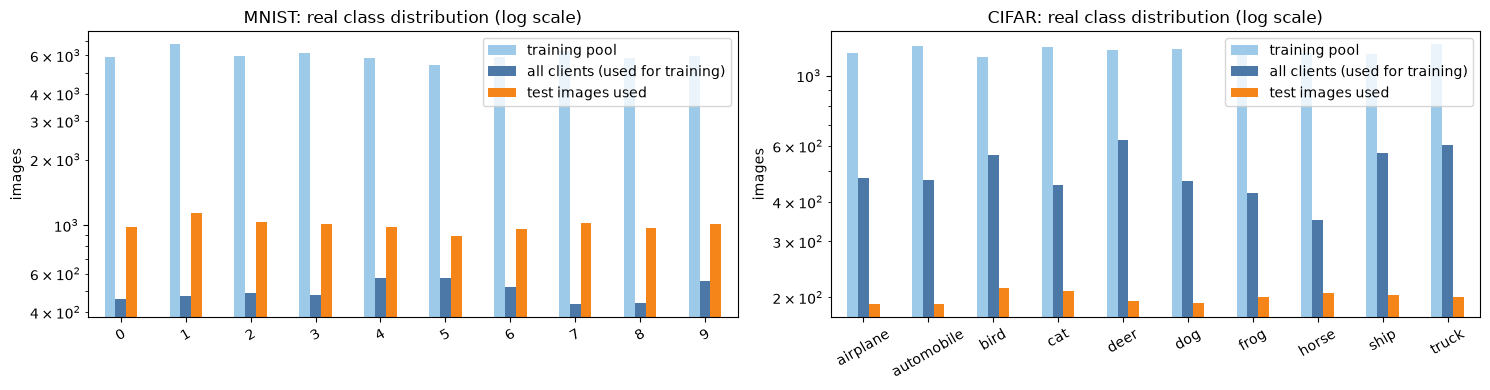

In [7]:
PALETTE = ["#4c78a8", "#f58518", "#54a24b", "#e45756", "#b279a2", "#72b7b2", "#9d755d", "#bab0ac", "#e377c2", "#17becf"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for k, (nm, d) in enumerate(DATA.items()):
    df = pd.DataFrame({"training pool": np.bincount(d["y_tr"], minlength=10),
                       "all clients (used for training)": np.bincount(d["Yc"].reshape(-1).numpy(), minlength=10),
                       "test images used": np.bincount(d["Yte"].numpy(), minlength=10)}, index=d["classes"])
    df.plot.bar(ax=ax[k], rot=30, color=["#9ecae9", "#4c78a8", "#f58518"]); ax[k].set_yscale("log")
    ax[k].set_title(f"{nm.upper()}: real class distribution (log scale)"); ax[k].set_ylabel("images")
plt.tight_layout(); plt.show()

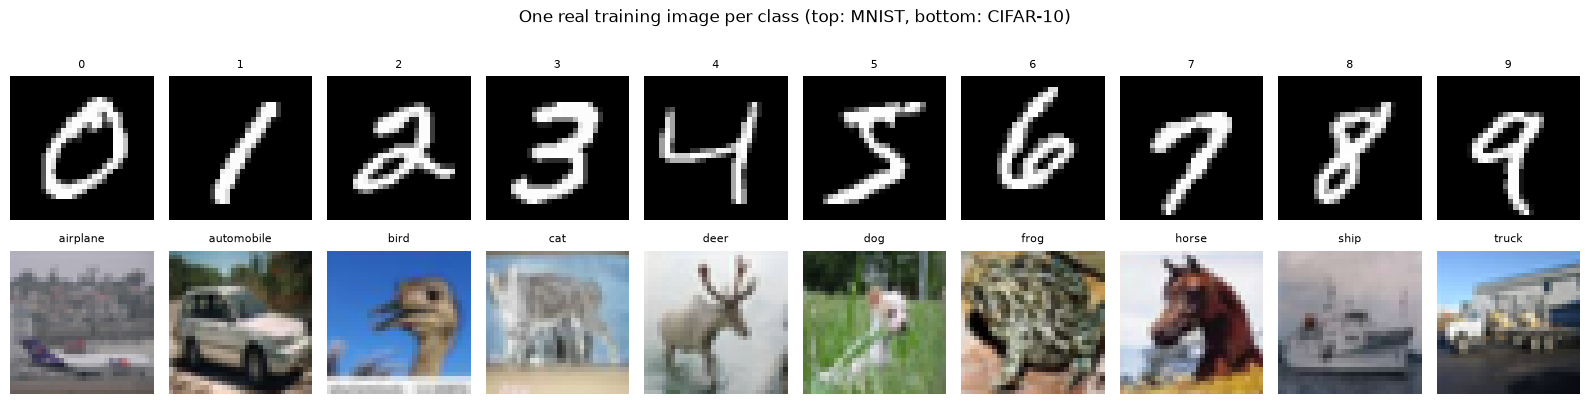

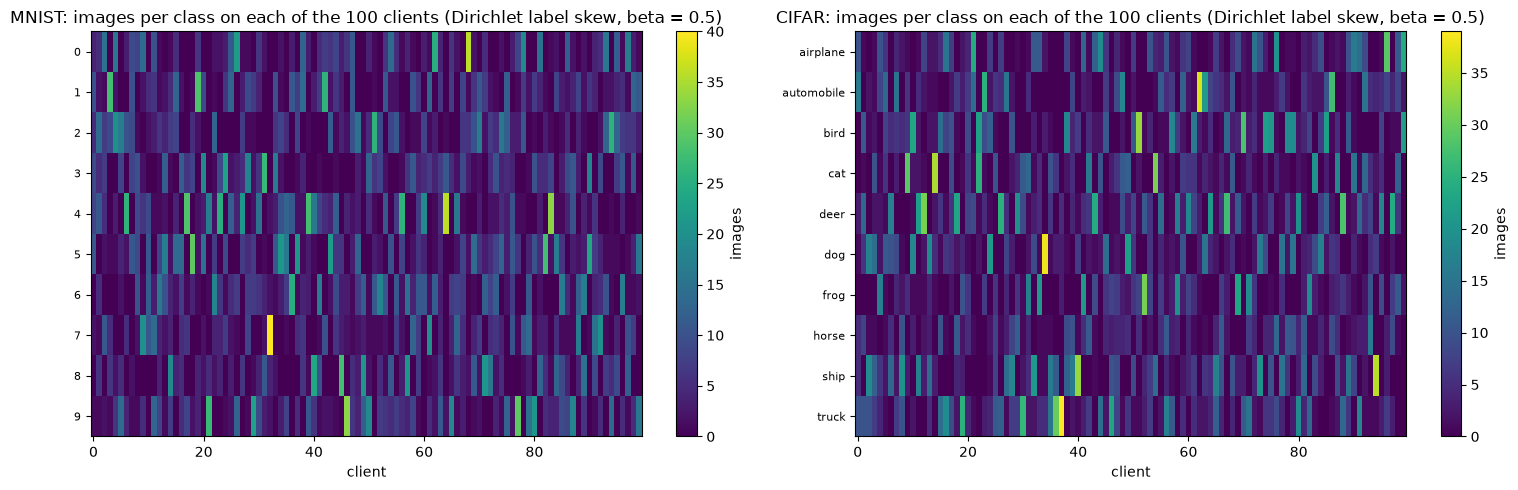

In [8]:
fig, ax = plt.subplots(2, 10, figsize=(16, 4.2))
for r, (nm, d) in enumerate(DATA.items()):
    for c in range(10):
        i = int(np.where(d["y_tr"] == c)[0][0])
        ax[r, c].imshow(d["raw_tr"][i], cmap="gray" if nm == "mnist" else None); ax[r, c].axis("off")
        ax[r, c].set_title(d["classes"][c], fontsize=8)
fig.suptitle("One real training image per class (top: MNIST, bottom: CIFAR-10)", y=1.0)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for k, (nm, d) in enumerate(DATA.items()):
    M = np.stack([np.bincount(d["Yc"][i].numpy(), minlength=10) for i in range(N_CLIENTS)])
    im = ax[k].imshow(M.T, aspect="auto", cmap="viridis"); ax[k].set_yticks(range(10)); ax[k].set_yticklabels(d["classes"], fontsize=8)
    ax[k].set_xlabel("client"); ax[k].set_title(f"{nm.upper()}: images per class on each of the {N_CLIENTS} clients (Dirichlet label skew, beta = {DIRICHLET_BETA})")
    plt.colorbar(im, ax=ax[k], label="images")
plt.tight_layout(); plt.show()

MNIST variance explained by the first two principal components: [0.116 0.083]


CIFAR variance explained by the first two principal components: [0.295 0.115]


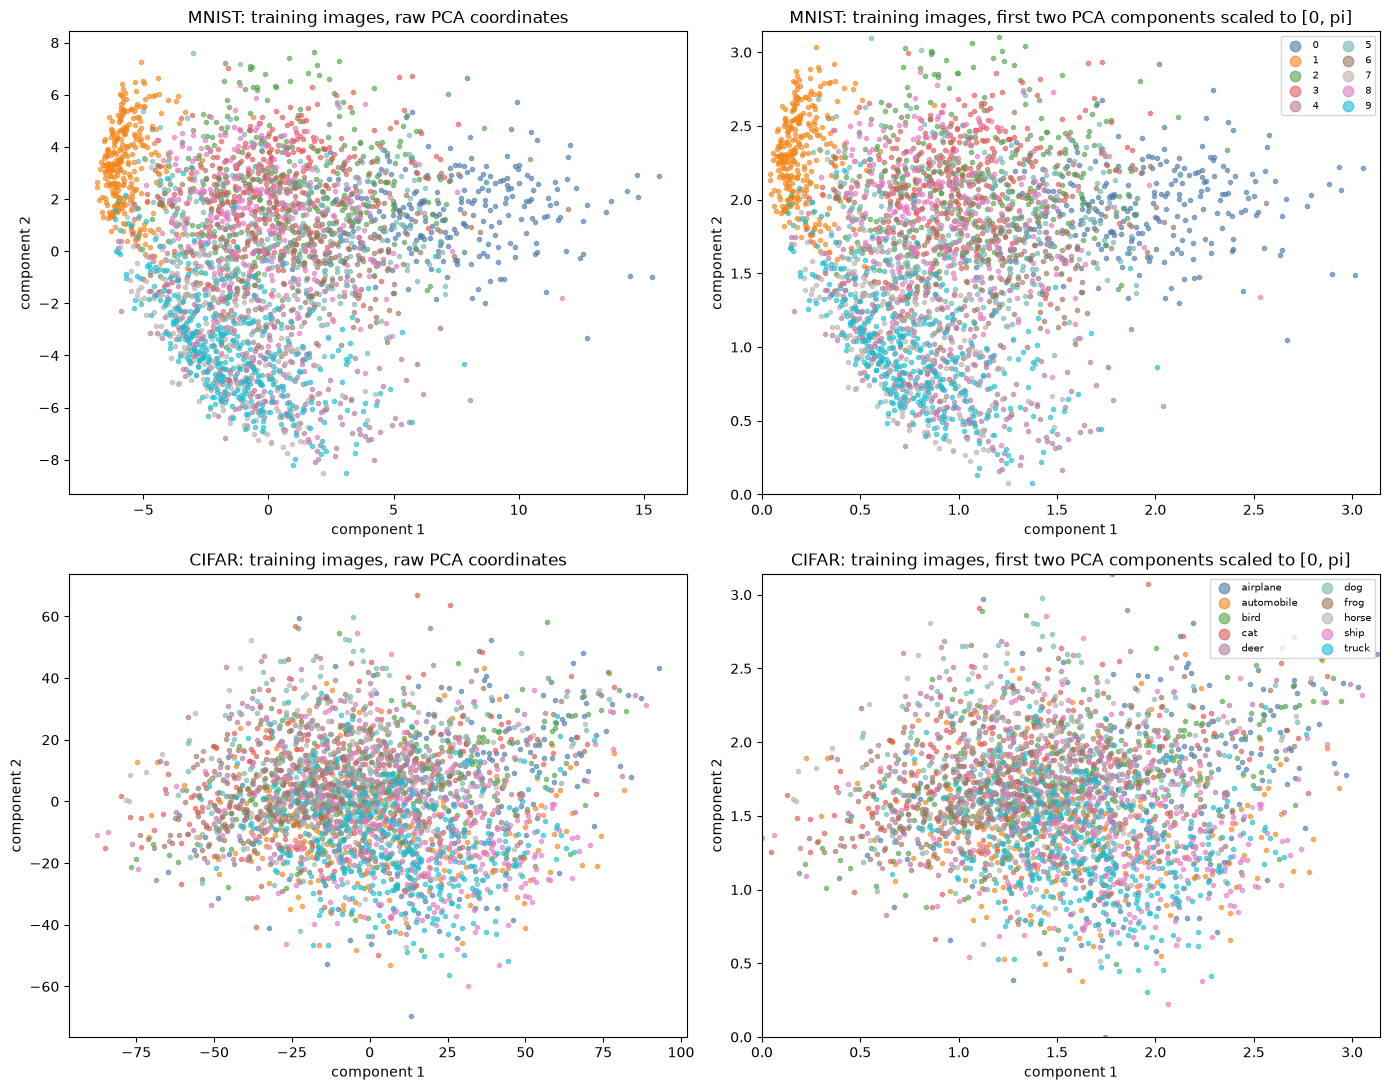

In [9]:
def pca_views(d, max_points=3000, seed=0):
    """Raw PCA coordinates fitted on the clients' training images, and the same coordinates scaled to [0, pi] (scaler fitted on the training images)."""
    X = d["Xc"].reshape(-1, int(np.prod(d["Xc"].shape[2:]))).numpy(); y = d["Yc"].reshape(-1).numpy()
    pca = PCA(n_components=2, random_state=SEED).fit(X)
    Z = pca.transform(X); A = np.clip(MinMaxScaler((0, np.pi)).fit(Z).transform(Z), 0, np.pi)
    sel = np.random.default_rng(seed).choice(len(Z), size=min(max_points, len(Z)), replace=False)
    return pca, Z[sel], A[sel], y[sel]

fig, ax = plt.subplots(2, 2, figsize=(14, 11))
for r, (nm, d) in enumerate(DATA.items()):
    pca, Z, A, y = pca_views(d)
    print(nm.upper(), "variance explained by the first two principal components:", np.round(pca.explained_variance_ratio_, 3))
    for c in range(10):
        m = y == c
        ax[r, 0].scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.6, color=PALETTE[c], label=d["classes"][c])
        ax[r, 1].scatter(A[m, 0], A[m, 1], s=9, alpha=0.6, color=PALETTE[c], label=d["classes"][c])
    ax[r, 0].set_title(f"{nm.upper()}: training images, raw PCA coordinates"); ax[r, 1].set_title(f"{nm.upper()}: training images, first two PCA components scaled to [0, pi]")
    ax[r, 1].set_xlim(0, np.pi); ax[r, 1].set_ylim(0, np.pi)
    for a in ax[r]: a.set_xlabel("component 1"); a.set_ylabel("component 2")
    ax[r, 1].legend(markerscale=2.5, fontsize=7, ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

## 2. The 8-qubit quantum convolutional neural network

**Circuit (Section VI-A.2).** The paper uses an 8-qubit QCNN with three pairs of quantum convolution and pooling layers and 64 trainable parameters. The blocks below are those of the Qiskit QCNN tutorial (a convolution block and a pooling block
have 3 rotation angles each; the pooling block entangles a "source" wire with a "sink" wire after which the source is no longer touched). The layout is:

* encoding: `RY(angle_q)` on every qubit `q` (the 8 angles are produced by a classical, trainable encoder; this is the one place where the paper is silent);
* layer 1: 8 convolution blocks on the ring (0,1), (2,3), (4,5), (6,7), (1,2), (3,4), (5,6), (7,0), then 4 pooling blocks 0->1, 2->3, 4->5, 6->7 (active qubits afterwards: 1, 3, 5, 7);
* layer 2: 4 convolution blocks (1,3), (5,7), (3,5), (7,1), then 2 pooling blocks 1->3, 5->7 (active: 3, 7);
* layer 3: 2 convolution blocks (3,7), (7,3), then 1 pooling block 3->7 (active: 7);
* a final trainable `RY` on qubit 7; the paper's "quantum fully connected layer + measurement layer" is realised as the measurement of `<Z>` on all 8 qubits followed by a classical `Linear(8, 10)` (`# CHOICE`).

The trainable circuit angles: 21 blocks x 3 + 1 = **64**, as in the paper.

**Simulation.** The reference object is a PennyLane QNode (`default.qubit`, PyTorch interface). Training 100 clients for many rounds with that QNode would be far too slow on a CPU, so all clients of all runs are simulated *together* by an exact
state-vector simulator written for batches (`qcnn_expvals`): the 21 block unitaries of every client are built in one batched call and applied to the 256-amplitude state with `torch.einsum`. The cell below builds the QNode (blocks and elementary gates) and asserts that
the simulator reproduces its `<Z_q>` values and its gradients to 1e-10, so what is trained is exactly the drawn circuit.

In [10]:
# ---------------- the 8-qubit QCNN: layout of the conv / pool blocks ----------------
# Pair (a, b) = wires the block acts on. For a pooling block a is the "source" (not touched again) and b the "sink" (kept).
STAGES = [
    ("conv", [(0, 1), (2, 3), (4, 5), (6, 7)]),      # layer 1, convolution (even pairs)
    ("conv", [(1, 2), (3, 4), (5, 6), (7, 0)]),      # layer 1, convolution (odd pairs, the ring closes with 7-0)
    ("pool", [(0, 1), (2, 3), (4, 5), (6, 7)]),      # layer 1, pooling  -> active qubits 1, 3, 5, 7
    ("conv", [(1, 3), (5, 7)]),                      # layer 2, convolution on the 4 active qubits
    ("conv", [(3, 5), (7, 1)]),
    ("pool", [(1, 3), (5, 7)]),                      # layer 2, pooling  -> active qubits 3, 7
    ("conv", [(3, 7)]),                              # layer 3, convolution on the 2 active qubits
    ("conv", [(7, 3)]),
    ("pool", [(3, 7)]),                              # layer 3, pooling  -> active qubit 7
]
FINAL_QUBIT = 7                                       # CHOICE: one final trainable RY(phi) on the last active qubit (brings the count to the paper's 64)
N_CONV = sum(len(p) for k, p in STAGES if k == "conv")      # 14 blocks x 3 parameters
N_POOL = sum(len(p) for k, p in STAGES if k == "pool")      # 7 blocks x 3 parameters
N_CIRC = 3 * (N_CONV + N_POOL) + 1                           # = 64
assert N_QUBITS == 8 and N_CIRC == 64, (N_QUBITS, N_CIRC)

# ---------------- small differentiable gate library (batched over leading dimensions) ----------------
def rz_m(a):
    c, s, z = torch.cos(a / 2), torch.sin(a / 2), torch.zeros_like(a)
    re = torch.stack([torch.stack([c, z], -1), torch.stack([z, c], -1)], -2)
    im = torch.stack([torch.stack([-s, z], -1), torch.stack([z, s], -1)], -2)
    return torch.complex(re, im)

def ry_m(a):
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    re = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
    return torch.complex(re, torch.zeros_like(re))

_CX01 = [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]]      # control = first wire
_CX10 = [[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]]      # control = second wire
_CONST = {}
def _const(name, dtype):
    key = (name, dtype)
    if key not in _CONST:
        I2 = torch.eye(2, dtype=dtype)
        rzm = rz_m(torch.tensor(-math.pi / 2, dtype=torch.float64 if dtype == torch.complex128 else torch.float32))
        rzp = rz_m(torch.tensor(math.pi / 2, dtype=torch.float64 if dtype == torch.complex128 else torch.float32))
        cx01, cx10 = torch.tensor(_CX01, dtype=dtype), torch.tensor(_CX10, dtype=dtype)
        _CONST[(("first", dtype))] = cx10 @ torch.kron(I2, rzm)                      # RZ(-pi/2)_b then CX(b->a)
        _CONST[(("last_conv", dtype))] = torch.kron(rzp, I2) @ cx10                   # CX(b->a) then RZ(pi/2)_a
        _CONST[(("cx01", dtype))] = cx01
        _CONST[(("I2", dtype))] = I2
    return _CONST[key]

def block_unitaries(p_conv, p_pool):
    """4x4 unitaries of all conv blocks (p_conv: (K, Nc, 3)) and all pool blocks (p_pool: (K, Np, 3)), computed in one batched pass.
    Wire order (first, second) = (a, b); `first` is the most significant bit.
    conv:  RZ(-pi/2)_b  CX(b->a)  RZ(p0)_a  RY(p1)_b  CX(a->b)  RY(p2)_b  CX(b->a)  RZ(pi/2)_a      (Qiskit QCNN tutorial blocks)
    pool:  RZ(-pi/2)_b  CX(b->a)  RZ(p0)_a  RY(p1)_b  CX(a->b)  RY(p2)_b"""
    p = torch.cat([p_conv, p_pool], 1)                                              # (K, Nc+Np, 3)
    cdt = torch.complex128 if p.dtype == torch.float64 else torch.complex64
    C1, Clast, CX01, I2 = _const("first", cdt), _const("last_conv", cdt), _const("cx01", cdt), _const("I2", cdt)
    a0 = p[..., 0]
    e_m, e_p = torch.polar(torch.ones_like(a0), -a0 / 2), torch.polar(torch.ones_like(a0), a0 / 2)
    diag = torch.stack([e_m, e_m, e_p, e_p], -1)                                    # kron(RZ(p0), I) is diagonal
    U = diag[..., :, None] * C1                                                     # kron(RZ(p0), I) @ C1
    ry1 = ry_m(p[..., 1]); ry2 = ry_m(p[..., 2])
    B1 = torch.einsum("ij,...kl->...ikjl", I2, ry1).reshape(*p.shape[:-1], 4, 4)    # kron(I, RY(p1))
    B2 = torch.einsum("ij,...kl->...ikjl", I2, ry2).reshape(*p.shape[:-1], 4, 4)    # kron(I, RY(p2))
    U = B2 @ CX01 @ B1 @ U
    nc = p_conv.shape[1]
    return torch.cat([Clast @ U[:, :nc], U[:, nc:]], 1)                             # conv blocks get the closing CX(b->a), RZ(pi/2)_a

# ---------------- state-vector machinery: wires 0..7, wire 0 = most significant bit (PennyLane convention) ----------------
NQ = N_QUBITS; DIM = 2 ** NQ
_L = "abcdefgh"
_EQ = {}
for _k, _pairs in STAGES:
    for (_a, _b) in _pairs:
        _out = list(_L); _out[_a] = "i"; _out[_b] = "j"
        _EQ[(_a, _b)] = f"kz{_L},kij{_L[_a]}{_L[_b]}->kz{''.join(_out)}"
_EQ_FINAL = f"kz{_L},kjh->kz{_L[:-1]}j"
_EQ_PROD = ",".join(f"kz{c}" for c in _L) + "->kz" + _L
SIGNS = torch.tensor([[1.0 - 2 * ((i >> (NQ - 1 - q)) & 1) for q in range(NQ)] for i in range(DIM)])     # (256, 8): eigenvalue of Z_q on basis state i

def qcnn_expvals(ang, circ):
    """Exact simulation of the QCNN for K clients at once. ang (K, B, 8) encoding angles, circ (K, 64) trainable angles -> <Z_q> (K, B, 8)."""
    cdt = torch.complex128 if ang.dtype == torch.float64 else torch.complex64
    K, B = ang.shape[:2]
    n3 = 3 * (N_CONV + N_POOL)
    conv_p, pool_p, off = [], [], 0
    for kind, pairs in STAGES:
        k = 3 * len(pairs); (conv_p if kind == "conv" else pool_p).append(circ[:, off:off + k].reshape(K, len(pairs), 3)); off += k
    U = block_unitaries(torch.cat(conv_p, 1), torch.cat(pool_p, 1)).reshape(K, N_CONV + N_POOL, 2, 2, 2, 2)
    c, s = torch.cos(ang / 2), torch.sin(ang / 2)
    v = torch.stack([c, s], -1)                                                     # RY(ang_q)|0> = (cos, sin) on every qubit
    st = torch.einsum(_EQ_PROD, *[v[:, :, q] for q in range(NQ)]).to(cdt)           # (K, B, 2, 2, 2, 2, 2, 2, 2, 2)
    ic, ip = 0, N_CONV
    for kind, pairs in STAGES:
        for ab in pairs:
            if kind == "conv": u = U[:, ic]; ic += 1
            else: u = U[:, ip]; ip += 1
            st = torch.einsum(_EQ[ab], st, u)
    assert FINAL_QUBIT == NQ - 1
    st = torch.einsum(_EQ_FINAL, st, ry_m(circ[:, n3]).to(cdt))                    # final RY on the last active qubit
    return (st.real ** 2 + st.imag ** 2).reshape(K, B, DIM) @ SIGNS.to(ang.dtype)

# ---------------- reference circuit: the same QCNN as a PennyLane QNode ----------------
import pennylane as qml

def conv_gates(p, wires):
    a, b = wires
    qml.RZ(-math.pi / 2, wires=b); qml.CNOT(wires=[b, a]); qml.RZ(p[0], wires=a); qml.RY(p[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RY(p[2], wires=b); qml.CNOT(wires=[b, a]); qml.RZ(math.pi / 2, wires=a)

def pool_gates(p, wires):
    a, b = wires
    qml.RZ(-math.pi / 2, wires=b); qml.CNOT(wires=[b, a]); qml.RZ(p[0], wires=a); qml.RY(p[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RY(p[2], wires=b)

class QConv(qml.operation.Operation):
    """Convolution block (3 parameters, 2 wires) of the QCNN; drawn as one box, executed as its 8 elementary gates."""
    num_wires = 2; num_params = 3; ndim_params = (0, 0, 0)
    @staticmethod
    def compute_decomposition(p0, p1, p2, wires):
        with qml.queuing.AnnotatedQueue() as q:
            conv_gates([p0, p1, p2], wires)
        return q.queue

class QPool(qml.operation.Operation):
    """Pooling block (3 parameters, 2 wires): source wire a, sink wire b; the source is not used again."""
    num_wires = 2; num_params = 3; ndim_params = (0, 0, 0)
    @staticmethod
    def compute_decomposition(p0, p1, p2, wires):
        with qml.queuing.AnnotatedQueue() as q:
            pool_gates([p0, p1, p2], wires)
        return q.queue

dev = qml.device("default.qubit", wires=NQ)

def qcnn_circuit(ang, circ, blocks=True):
    for q in range(NQ):
        qml.RY(ang[..., q], wires=q)                                                              # angle encoding of the 8 features
    off = 0
    for kind, pairs in STAGES:
        for ab in pairs:
            p = [circ[off], circ[off + 1], circ[off + 2]]; off += 3
            if blocks: (QConv if kind == "conv" else QPool)(*p, wires=list(ab))
            else: (conv_gates if kind == "conv" else pool_gates)(p, list(ab))
    qml.RY(circ[off], wires=FINAL_QUBIT)                                                          # final trainable rotation
    return [qml.expval(qml.PauliZ(q)) for q in range(NQ)]                                         # <Z> on every qubit

qcnn_qnode = qml.QNode(lambda ang, circ: qcnn_circuit(ang, circ, True), dev, interface="torch", diff_method="backprop")
qcnn_qnode_flat = qml.QNode(lambda ang, circ: qcnn_circuit(ang, circ, False), dev, interface="torch", diff_method="backprop")

# ---------------- equivalence check: fast stacked simulator == PennyLane QNode (values and gradients) ----------------
g_chk = torch.Generator().manual_seed(SEED)
ang_t = (torch.rand(6, NQ, generator=g_chk, dtype=torch.float64) * 2 - 1) * math.pi
circ_t = ((torch.rand(N_CIRC, generator=g_chk, dtype=torch.float64) * 2 - 1) * math.pi).requires_grad_(True)
ref = torch.stack(qcnn_qnode(ang_t, circ_t), -1)                                                  # (6, 8) from PennyLane
ref_flat = torch.stack(qcnn_qnode_flat(ang_t, circ_t), -1)
fast = qcnn_expvals(ang_t[None], circ_t[None])[0]                                                 # (6, 8) from the stacked simulator
w8 = torch.arange(1, 9, dtype=torch.float64)
gr_ref = torch.autograd.grad((ref * w8).sum(), circ_t)[0]
gr_fast = torch.autograd.grad((fast * w8).sum(), circ_t)[0]
print("max |QNode (blocks) - stacked simulator| :", float((ref - fast).abs().max()))
print("max |QNode (flat gates) - QNode (blocks)|:", float((ref_flat - ref).abs().max()))
print("max |gradient QNode - gradient simulator|:", float((gr_ref - gr_fast).abs().max()))
assert torch.allclose(ref, fast, atol=1e-10) and torch.allclose(ref_flat, ref, atol=1e-10) and torch.allclose(gr_ref, gr_fast, atol=1e-10)
print("the stacked simulator used for training is the PennyLane circuit (values and gradients agree to 1e-10).")

max |QNode (blocks) - stacked simulator| : 1.27675647831893e-15
max |QNode (flat gates) - QNode (blocks)|: 0.0
max |gradient QNode - gradient simulator|: 2.930988785010413e-14
the stacked simulator used for training is the PennyLane circuit (values and gradients agree to 1e-10).


## Quantum Circuit Architecture

The first picture is the QNode `qcnn_qnode` as written (each convolution block `QConv` and pooling block `QPool` is one box, with the angle-encoding `RY` gates in front and a `<Z>` measurement of every qubit at the end).
The second picture is the device-level circuit after PennyLane expanded every box into the elementary gates `RZ`, `CNOT`, `RY` that are actually executed. A cell then asserts that the executed gate list is exactly the gate list implied by
`STAGES` (which the fast simulator implements) and prints qubit count, depth and parameter counts.
Assumptions where the paper omits details: the block types and their arrangement (Qiskit QCNN tutorial blocks, ring convolution, three conv-pool pairs), the angle encoding (`RY`), the final `RY(phi)` that completes the 64 parameters, and the read-out
(`<Z>` on all 8 qubits, classical `Linear(8, 10)`).

Matplotlib is building the font cache; this may take a moment.


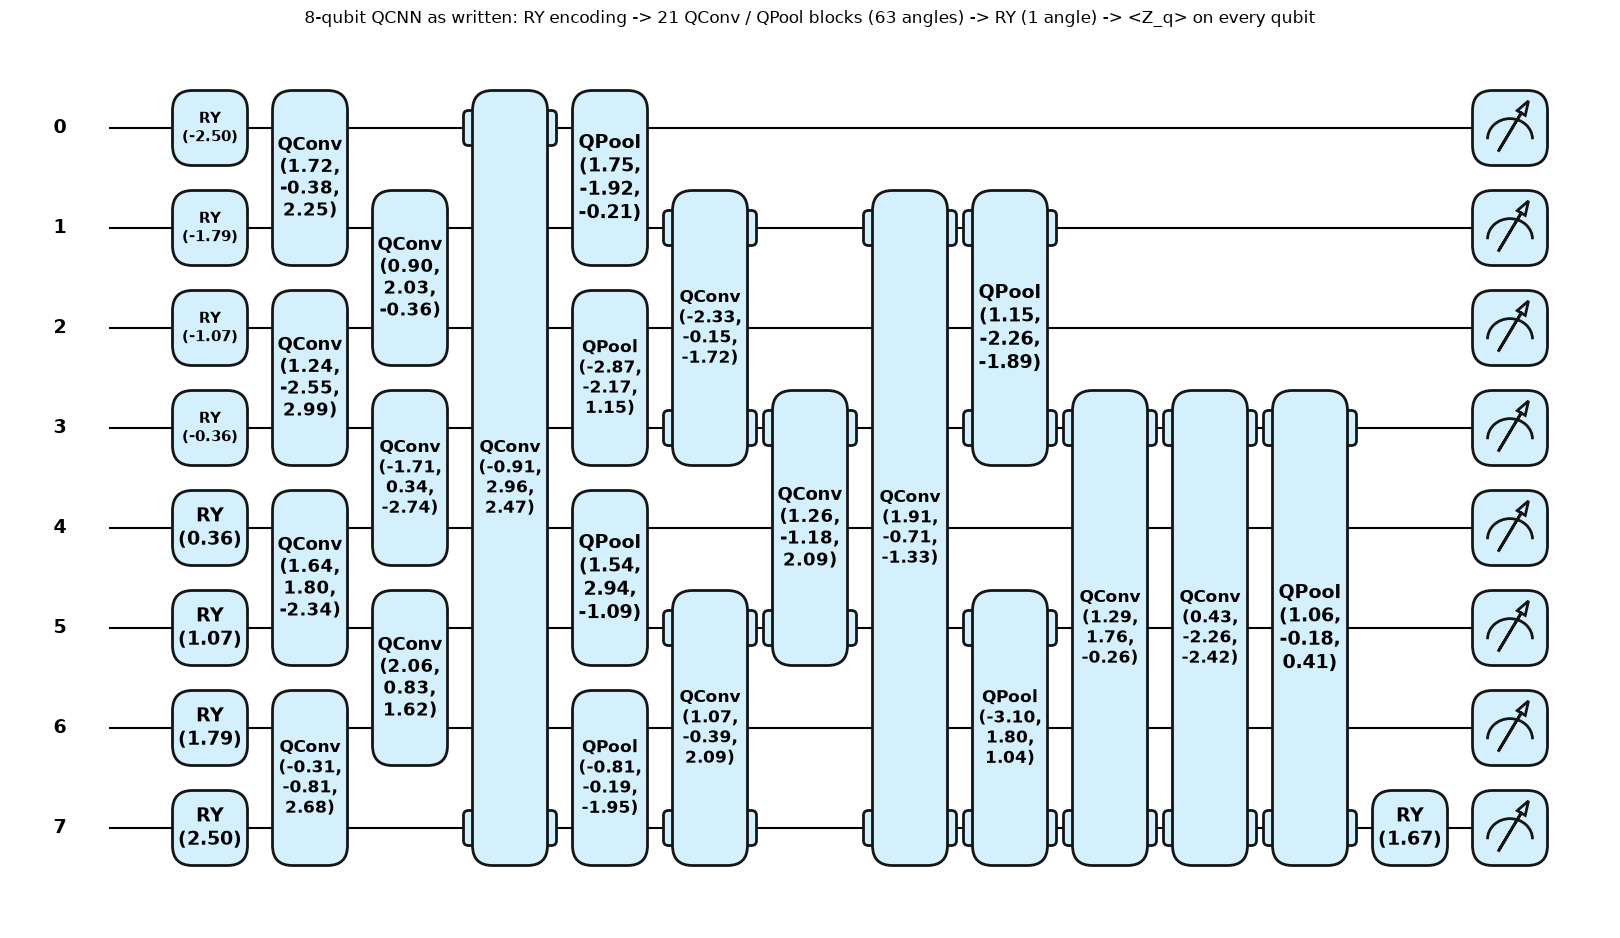

Matplotlib is building the font cache; this may take a moment.


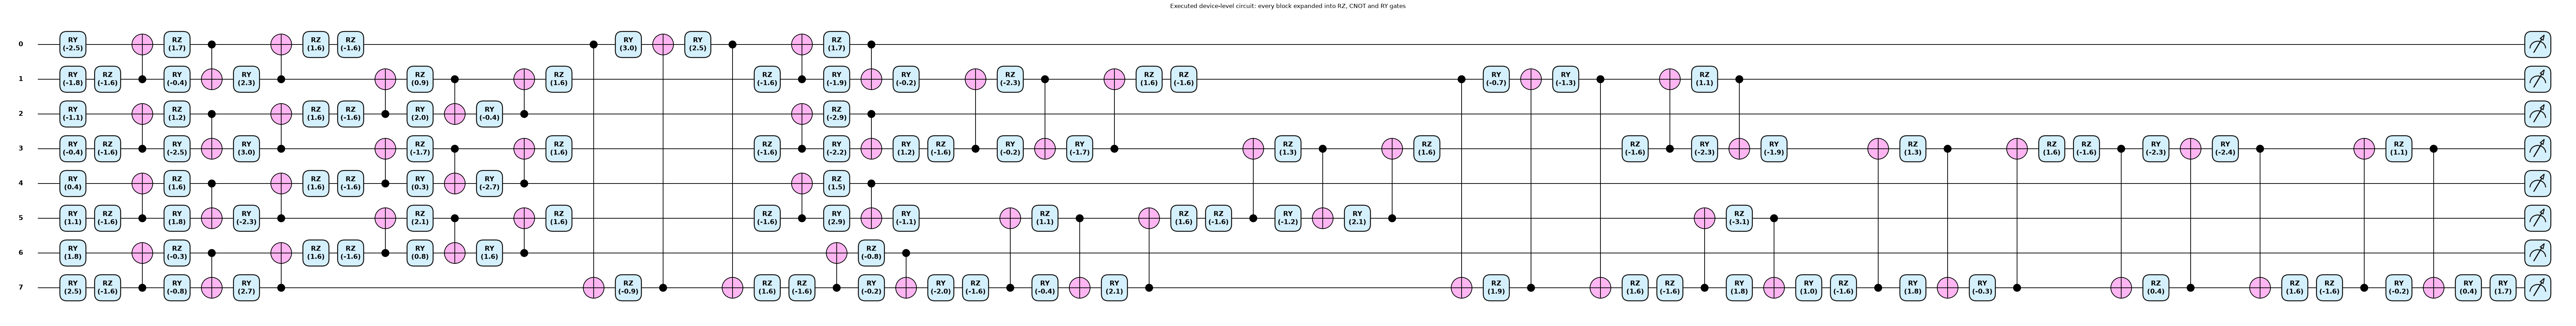

In [11]:
ang_demo = torch.tensor(np.linspace(-2.5, 2.5, N_QUBITS), dtype=torch.float64)
circ_demo = torch.tensor(np.random.default_rng(SEED).uniform(-np.pi, np.pi, N_CIRC))
fig1, _ = qml.draw_mpl(qcnn_qnode, decimals=2, style="pennylane")(ang_demo, circ_demo)
fig1.suptitle("8-qubit QCNN as written: RY encoding -> 21 QConv / QPool blocks (63 angles) -> RY (1 angle) -> <Z_q> on every qubit", y=1.02); plt.show()
fig2, _ = qml.draw_mpl(qcnn_qnode, decimals=1, level="device", style="pennylane")(ang_demo, circ_demo)
fig2.suptitle("Executed device-level circuit: every block expanded into RZ, CNOT and RY gates", y=1.02); plt.show()

In [12]:
tape = qml.workflow.construct_batch(qcnn_qnode, level="device")(ang_demo, circ_demo)[0][0]
ops = [(o.name, tuple(o.wires.tolist())) for o in tape.operations]
expected = [("RY", (q,)) for q in range(NQ)]
for kind, pairs in STAGES:
    for (a, b) in pairs:
        expected += [("RZ", (b,)), ("CNOT", (b, a)), ("RZ", (a,)), ("RY", (b,)), ("CNOT", (a, b)), ("RY", (b,))]
        if kind == "conv": expected += [("CNOT", (b, a)), ("RZ", (a,))]
expected += [("RY", (FINAL_QUBIT,))]
assert ops == expected, "executed circuit differs from the gate list implied by STAGES"
print("assertion passed: the executed device circuit = 8 encoding RY + 14 conv blocks x 8 gates + 7 pool blocks x 6 gates + 1 final RY")

def circuit_depth(operations, n_wires):
    level = [0] * n_wires
    for o in operations:
        ws = list(o.wires); dd = max(level[w] for w in ws) + 1
        for w in ws: level[w] = dd
    return max(level)

n_rot = sum(1 for n, _ in ops if n in ("RX", "RY", "RZ")); n_cnot = sum(1 for n, _ in ops if n == "CNOT")
print("qubits                         :", NQ)
print("circuit depth (device level)   :", circuit_depth(tape.operations, NQ))
print("gates                          :", len(ops), f"({n_rot} rotations incl. {NQ} encoding RY, {n_cnot} CNOT)")
print("trainable circuit parameters   :", N_CIRC, "(= 21 blocks x 3 + 1; the paper states 64)")
print("data-dependent angles          :", NQ, "(one RY per qubit, produced by the classical encoder)")
print("measurements                   :", NQ, "Pauli-Z expectation values -> classical Linear(8, 10) read-out (90 parameters)")

assertion passed: the executed device circuit = 8 encoding RY + 14 conv blocks x 8 gates + 7 pool blocks x 6 gates + 1 final RY
qubits                         : 8
circuit depth (device level)   : 59
gates                          : 163 (107 rotations incl. 8 encoding RY, 56 CNOT)
trainable circuit parameters   : 64 (= 21 blocks x 3 + 1; the paper states 64)
data-dependent angles          : 8 (one RY per qubit, produced by the classical encoder)
measurements                   : 8 Pauli-Z expectation values -> classical Linear(8, 10) read-out (90 parameters)


## 3. The hybrid model and the federated engine

**Model.** For every client the model is `image -> classical encoder -> 8 angles -> 8-qubit QCNN -> <Z> on 8 qubits -> Linear(8, 10) -> 10 outputs`, trained with the **MSE loss** between the outputs and the one-hot label (Table II).
The encoder is the part the paper does not describe (`# CHOICE`): MNIST uses `Linear(196, 8)` on the 2x2 average-pooled image; CIFAR-10 uses two small convolutions and `Linear(256, 8)`. The *classical control* replaces the circuit by a classical
`tanh(angles @ W)` layer with the same 64 parameters (`Wc` is 8 x 8), so "classical FL" differs from "quantum FL" only in this layer.

**One federation round** (`run_group`):

1. the server samples `K` clients; each starts from the global model;
2. **local training** for one epoch (`n / 10` steps of Adam, lr 0.005, fresh Adam state), either plain mini-batch gradient steps (`sgd`: FedAvg-style methods) or the support/query meta-update of Eq. 3 (`meta`: ADP-QFL and "QFL without estimation");
3. the client's update `delta = local - global` goes through the **privacy pipeline**:
   * *estimation* (ADP-QFL only): the sparsest estimate `delta^` with `||delta^ - delta|| <= EST_REL_ERR * ||delta||` (largest-magnitude entries are kept), and the *consensus filter* (a client whose `||delta||` exceeds `SEL_KAPPA` times the round median is not aggregated);
   * *clipping* to `CLIP_C` (bounds each client's influence = sensitivity of the Gaussian mechanism);
   * *Gaussian noise* with standard deviation `sigma_t = z * CLIP_C / sqrt(1 + ALPHA_DECAY * t)` ("adaptive", Section IV-C) or `z * CLIP_C` ("fixed") on every transmitted coordinate;
4. the server averages the transmitted updates of the accepted clients and adds the average to the global model.

All runs of the same model and local procedure are executed **in lock-step as one stacked tensor** (different noise levels, participation rates, estimation on/off ...): the cost of such tiny circuits is dominated by Python overhead, so stacking 100+ clients costs
about the same per step as stacking 10. Each run keeps its own global model, its own random client sampling and its own noise.

In [13]:
import torch.nn.functional as F
DT = torch.float32

# ---------------- parameter layout of a model (all K clients share one flat layout) ----------------
class Layout:
    def __init__(self, items):
        self.items, o = [], 0
        for name, shape, init in items:
            n = int(np.prod(shape)); self.items.append((name, shape, init, o, n)); o += n
        self.P = o
    def unpack(self, th):
        K = th.shape[0]
        return {name: th[:, o:o + n].reshape(K, *shape) for name, shape, init, o, n in self.items}
    def init(self, rng):
        v = np.zeros(self.P)
        for name, shape, init, o, n in self.items:
            kind, *arg = init.split(":")
            if kind == "normal": v[o:o + n] = rng.normal(0, float(arg[0]), n)
            elif kind == "uniform": v[o:o + n] = rng.uniform(-float(arg[0]), float(arg[0]), n)
        return torch.tensor(v, dtype=DT)

class Model:
    """Classical encoder (images -> 8 angles) + [QCNN circuit | classical 8x8 control] + classical read-out Linear(8 -> 10). Applies to K clients at once."""
    def __init__(self, ds, kind):
        self.ds, self.kind = ds, kind
        items = []
        if ds == "mnist":
            items += [("We", (196, 8), "normal:%.5f" % (1 / math.sqrt(196))), ("be", (8,), "zeros")]
        else:
            items += [("c1w", (8, 3, 3, 3), "normal:%.5f" % math.sqrt(2 / 27)), ("c1b", (8,), "zeros"),
                      ("c2w", (16, 8, 3, 3), "normal:%.5f" % math.sqrt(2 / 72)), ("c2b", (16,), "zeros"),
                      ("We", (256, 8), "normal:%.5f" % (1 / math.sqrt(256))), ("be", (8,), "zeros")]
        self.n_enc = sum(int(np.prod(s)) for _, s, _ in items)
        if kind == "qcnn": items += [("circ", (N_CIRC,), "uniform:1.5708")]                  # CHOICE: initial circuit angles U[-pi/2, pi/2]
        else:              items += [("Wc", (8, 8), "normal:0.5")]                              # classical control with the same number (64) of trainable parameters
        items += [("Wh", (8, 10), "normal:0.5"), ("bh", (10,), "zeros")]
        self.layout = Layout(items); self.P = self.layout.P
    def angles(self, p, x):
        if self.ds == "mnist":
            a = torch.einsum("kbf,kfq->kbq", x, p["We"]) + p["be"][:, None, :]
        else:
            K, B = x.shape[:2]
            z = x.permute(1, 0, 2, 3, 4).reshape(B, K * 3, 32, 32)
            z = F.max_pool2d(F.relu(F.conv2d(z, p["c1w"].reshape(K * 8, 3, 3, 3), p["c1b"].reshape(-1), padding=1, groups=K)), 2)
            z = F.max_pool2d(F.relu(F.conv2d(z, p["c2w"].reshape(K * 16, 8, 3, 3), p["c2b"].reshape(-1), padding=1, groups=K)), 4)
            z = z.reshape(B, K, 256).permute(1, 0, 2)
            a = torch.einsum("kbf,kfq->kbq", z, p["We"]) + p["be"][:, None, :]
        return math.pi * torch.tanh(a)                                                      # CHOICE: angles in (-pi, pi)
    def forward(self, th, x):
        p = self.layout.unpack(th)
        ang = self.angles(p, x)
        h = qcnn_expvals(ang, p["circ"]) if self.kind == "qcnn" else torch.tanh(torch.einsum("kbq,kqr->kbr", ang, p["Wc"]))
        return torch.einsum("kbq,kqc->kbc", h, p["Wh"]) + p["bh"][:, None, :]
    def loss(self, th, x, y):
        out = self.forward(th, x)
        return ((out - F.one_hot(y, 10).to(out.dtype)) ** 2).mean((1, 2))                   # MSE loss as in Table II; one value per client

@torch.no_grad()
def evaluate(model, G, X, Y, chunk=None):
    """G (R, P) global models of R runs, X (N, ...) shared test images -> accuracy and MSE per run."""
    R = G.shape[0]; correct = torch.zeros(R); loss = torch.zeros(R)
    chunk = chunk or max(32, 8000 // R)                                      # keep R * chunk states in memory moderate
    for i in range(0, len(Y), chunk):
        xb = X[i:i + chunk][None].expand(R, *X[i:i + chunk].shape); yb = Y[i:i + chunk][None].expand(R, -1)
        out = model.forward(G, xb)
        correct += (out.argmax(-1) == yb).float().sum(1); loss += ((out - F.one_hot(yb, 10).to(out.dtype)) ** 2).mean(2).sum(1)
    return (correct / len(Y)).numpy(), (loss / len(Y)).numpy()

# ---------------- one federation round for many runs at once ----------------
def sigma_at(spec, t):
    """Noise standard deviation of the Gaussian added to every transmitted coordinate in round t (t = 0, 1, ...)."""
    if spec["noise"] == "none": return 0.0
    base = spec["z"] * CLIP_C
    return base / math.sqrt(1.0 + ALPHA_DECAY * t) if spec["noise"] == "adaptive" else base       # sigma_t^2 = sigma_0^2 / (1 + alpha t)  (Section IV-C)

def sparse_estimate(delta, rel_err):
    """Sparsest estimate d_hat of each row of delta with ||d_hat - delta|| <= rel_err * ||delta||: keep the largest-magnitude entries (Algorithm 1, line 15 / Eq. 7)."""
    a2 = delta ** 2
    srt, order = torch.sort(a2, dim=1)                                       # ascending squared magnitudes
    csum = torch.cumsum(srt, 1)
    thr = (rel_err ** 2) * a2.sum(1, keepdim=True)
    n_drop = (csum <= thr).sum(1)                                            # largest number of smallest entries whose total energy stays within the error bound
    cut = srt.gather(1, (n_drop - 1).clamp(min=0)[:, None])                  # squared magnitude of the largest dropped entry
    mask = (a2 > cut) | (n_drop[:, None] == 0)
    return delta * mask, mask

def local_training(model, theta0, Xk, Yk, local, gen, second_order=False):
    """Local training of K clients stacked in one tensor. local = 'sgd' (plain mini-batch Adam) or 'meta' (support / query meta-gradient, Eq. 3-4). Adam, lr LR, fresh state each round."""
    K, n = Yk.shape
    th = theta0.clone(); m = torch.zeros_like(th); v = torch.zeros_like(th); step = 0
    ar = torch.arange(K)[:, None]
    for ep in range(LOCAL_EPOCHS):
        perm = torch.argsort(torch.rand(K, n, generator=gen), 1)
        for s in range(n // BATCH):
            idx = perm[:, s * BATCH:(s + 1) * BATCH]
            if local == "sgd":
                x, y = Xk[ar, idx], Yk[ar, idx]
                g = torch.autograd.grad(model.loss(th.requires_grad_(True), x, y).sum(), th)[0]
                th = th.detach()
            else:
                hb = BATCH // 2                                                   # CHOICE: each mini-batch of 10 is split into a support set (5) and a query set (5)
                xs, ys, xq, yq = Xk[ar, idx[:, :hb]], Yk[ar, idx[:, :hb]], Xk[ar, idx[:, hb:]], Yk[ar, idx[:, hb:]]
                th_ = th.detach().requires_grad_(True)
                gs = torch.autograd.grad(model.loss(th_, xs, ys).sum(), th_)[0]
                th_t = (th_ - META_ETA * gs).detach().requires_grad_(True)       # adapted parameters  theta~ = theta - eta * grad L(support)
                gq = torch.autograd.grad(model.loss(th_t, xq, yq).sum(), th_t)[0]
                if second_order:                                                  # exact (I - eta * Hessian_support(theta~)) grad_query(theta~)
                    gs2 = torch.autograd.grad(model.loss(th_t, xs, ys).sum(), th_t, create_graph=True)[0]
                    hv = torch.autograd.grad((gs2 * gq.detach()).sum(), th_t)[0]
                    g = gq - META_ETA * hv
                else:
                    g = gq                                                        # CHOICE: first-order meta-gradient (the eta*Hessian correction is dropped; see the check cell)
                th = th.detach()
            step += 1
            m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
            th = th - LR * (m / (1 - 0.9 ** step)) / ((v / (1 - 0.999 ** step)).sqrt() + 1e-8)
    return th.detach()

def run_group(model, data, specs, rounds, local, eval_every, log=print):
    """Run several federations in lock-step (all share the model, the client data and the local procedure; they differ in noise / participation / estimation).
    spec keys: name, K (clients per round), noise ('none'|'fixed'|'adaptive'), z (noise multiplier), estimation (bool), clip (bool), seed. Returns {name: history dict}."""
    R = len(specs)
    G = torch.stack([model.layout.init(np.random.default_rng(1000 + s["seed"])) for s in specs])           # same seed -> same initial global model
    rngs = [np.random.default_rng(2000 + s["seed"] + 17 * i) for i, s in enumerate(specs)]
    gen = torch.Generator().manual_seed(SEED + 5); gnoise = torch.Generator().manual_seed(SEED + 6)
    Xte, Yte = data["Xte"][:EVAL_TEST], data["Yte"][:EVAL_TEST]
    hist = {s["name"]: dict(round=[], test_acc=[], test_loss=[], accepted=[], comm=[], sigma=[], update_var=[], update_norm=[]) for s in specs}
    t0 = time.time()
    for t in range(rounds + 1):
        if t % eval_every == 0 or t == rounds:
            ta, tl = evaluate(model, G, Xte, Yte)
            for i, s in enumerate(specs):
                h = hist[s["name"]]; h["round"].append(t); h["test_acc"].append(float(ta[i])); h["test_loss"].append(float(tl[i]))
            if t % (5 * eval_every) == 0 or t == rounds:
                log(f"  round {t:4d}/{rounds}  " + "  ".join(f"{s['name']}={ta[i]*100:.1f}%" for i, s in enumerate(specs[:4])) + (" ..." if R > 4 else "") + f"   [{time.time()-t0:.0f}s]")
        if t == rounds: break
        sels = [rngs[i].choice(N_CLIENTS, size=s["K"], replace=False) for i, s in enumerate(specs)]
        allsel = np.concatenate(sels); bounds = np.cumsum([0] + [s["K"] for s in specs])
        theta0 = torch.cat([G[i][None].expand(s["K"], -1) for i, s in enumerate(specs)])
        theta = local_training(model, theta0, data["Xc"][allsel], data["Yc"][allsel], local, gen)
        delta = theta - theta0
        for i, s in enumerate(specs):
            sl = slice(bounds[i], bounds[i + 1]); d = delta[sl]; K = s["K"]
            norms = d.norm(dim=1)
            h = hist[s["name"]]
            if s["noise"] == "none" and not s["estimation"] and not s["clip"]:
                upd = d.mean(0); acc = K; comm = 1.0; sig = 0.0
            else:
                accepted = torch.ones(K, dtype=torch.bool); mask = torch.ones_like(d, dtype=torch.bool)
                if s["estimation"]:
                    d_hat, mask = sparse_estimate(d, EST_REL_ERR)                                     # model estimation: sparse estimate within the error bound b*lambda
                    accepted = norms <= SEL_KAPPA * norms.median()                                    # consensus filter: drop clients whose update is an outlier
                else:
                    d_hat = d
                if s["clip"]:
                    d_hat = d_hat * torch.clamp(CLIP_C / (d_hat.norm(dim=1, keepdim=True) + 1e-12), max=1.0)
                sig = sigma_at(s, t)
                noise = sig * torch.randn(d_hat.shape, generator=gnoise) * mask if sig > 0 else torch.zeros_like(d_hat)
                tx = (d_hat + noise)[accepted]
                upd = tx.mean(0) if tx.shape[0] > 0 else torch.zeros(model.P)
                acc = int(accepted.sum()); comm = float(mask[accepted].float().mean()) if acc > 0 else 0.0
            G[i] = G[i] + upd
            h["accepted"].append(acc); h["comm"].append(comm); h["sigma"].append(sig)
            h["update_var"].append(float(d.var(0).mean())); h["update_norm"].append(float(norms.mean()))
    for s in specs: hist[s["name"]]["seconds"] = time.time() - t0
    return hist, G

def final_eval(model, G, data, n_test, n_train, seed=SEED):
    """Larger final evaluation of the global models G (R, P): accuracy on n_test test images and on n_train of the clients' own training images."""
    ta, _ = evaluate(model, G, data["Xte"][:n_test], data["Yte"][:n_test])
    idx = np.random.default_rng(seed).choice(N_CLIENTS * N_PER_CLIENT, size=min(n_train, N_CLIENTS * N_PER_CLIENT), replace=False)
    tr, _ = evaluate(model, G, data["Xc"].reshape(-1, *data["Xc"].shape[2:])[idx], data["Yc"].reshape(-1)[idx])
    return ta, tr

In [14]:
for nm in ("mnist", "cifar"):
    for kind in ("qcnn", "classical"):
        m = Model(nm, kind)
        out = m.forward(m.layout.init(np.random.default_rng(0))[None], DATA[nm]["Xc"][:1, :4])
        print(f"{nm:6s} {kind:10s} trainable parameters per client: {m.P:6d} (encoder {m.n_enc}, {'circuit 64' if kind=='qcnn' else 'classical 8x8 layer 64'}, read-out 90) | output for 4 images: {tuple(out.shape)}")

mnist  qcnn       trainable parameters per client:   1730 (encoder 1576, circuit 64, read-out 90) | output for 4 images: (1, 4, 10)
mnist  classical  trainable parameters per client:   1730 (encoder 1576, classical 8x8 layer 64, read-out 90) | output for 4 images: (1, 4, 10)
cifar  qcnn       trainable parameters per client:   3602 (encoder 3448, circuit 64, read-out 90) | output for 4 images: (1, 4, 10)
cifar  classical  trainable parameters per client:   3602 (encoder 3448, classical 8x8 layer 64, read-out 90) | output for 4 images: (1, 4, 10)


## 4. MNIST experiments

Groups of runs (all on the same data; runs with the same seed start from the same initial global model):

* **ADP-QFL** (`meta` update, estimation + consensus filter, adaptive noise, clipping) at the five noise levels of Fig. 5 and at three participation rates (Fig. 6);
* **QFL (no estimation)**: ADP-QFL without the estimation / consensus filter (Fig. 7);
* **FedAvg-QCNN** without any privacy mechanism and **DP-FedAvg-QCNN** (clipping + fixed noise);
* **Classical FL (DP)** and a plain classical FedAvg (the circuit replaced by the 64-parameter classical layer), repeated for several seeds.

The test accuracy curves use `EVAL_TEST` test images (cheap, noisy); the final numbers use `FINAL_TEST` test images.

In [15]:
def mk(name, K, noise, z, est, clip=True, seed=0):
    return dict(name=name, K=K, noise=noise, z=z, estimation=est, clip=clip, seed=seed)

def run_dataset(ds, groups, rounds):
    """groups: list of (model kind, local procedure, specs). Returns {run name: result dict}."""
    out = {}
    for kind, local, specs in groups:
        if not specs: continue
        model = Model(ds, kind)
        print(f"--- {ds}: model = {kind}, local = {local}, {len(specs)} runs, {sum(s['K'] for s in specs)} client trainings per round, {rounds} rounds")
        hist, G = run_group(model, DATA[ds], specs, rounds, local, eval_every=max(1, rounds // 8))
        ta, tr = final_eval(model, G, DATA[ds], FINAL_TEST, FINAL_TRAIN)
        for i, s in enumerate(specs):
            out[s["name"]] = dict(spec=s, kind=kind, local=local, hist=hist[s["name"]], final_test=float(ta[i]), final_train=float(tr[i]), G=G[i].clone())
        print(f"    group time {hist[specs[0]['name']]['seconds']:.0f}s")
    return out

K_MAIN = int(FRAC_MAIN * N_CLIENTS)
A = [mk(f"ADP-QFL z={z:g}", K_MAIN, "adaptive", z, True) for z in NOISE_RUN]
A += [mk(f"ADP-QFL frac={f:g}", int(f * N_CLIENTS), "adaptive", Z_MAIN, True) for f in FRACS_RUN if f != FRAC_MAIN]
A += [mk("QFL (no estimation)", K_MAIN, "adaptive", Z_MAIN, False)]
B = [mk("FedAvg-QCNN (no DP)", K_MAIN, "none", 0.0, False, clip=False), mk("DP-FedAvg-QCNN", K_MAIN, "fixed", Z_MAIN, False)]
C = []
for sd in CLASSICAL_SEEDS:
    C += [mk(f"FedAvg-classical (no DP) s{sd}", K_MAIN, "none", 0.0, False, clip=False, seed=sd), mk(f"Classical FL (DP) s{sd}", K_MAIN, "fixed", Z_MAIN, False, seed=sd)]
for sd in MAIN_SEEDS[1:]:
    A += [mk(f"ADP-QFL z={Z_MAIN:g} s{sd}", K_MAIN, "adaptive", Z_MAIN, True, seed=sd), mk(f"QFL (no estimation) s{sd}", K_MAIN, "adaptive", Z_MAIN, False, seed=sd)]
    B += [mk(f"FedAvg-QCNN (no DP) s{sd}", K_MAIN, "none", 0.0, False, clip=False, seed=sd), mk(f"DP-FedAvg-QCNN s{sd}", K_MAIN, "fixed", Z_MAIN, False, seed=sd)]
assert f"ADP-QFL z={Z_MAIN:g}" in [s["name"] for s in A]
t_start = time.time()
RES_M = run_dataset("mnist", [("qcnn", "meta", A), ("qcnn", "sgd", B), ("classical", "sgd", C)], ROUNDS_MNIST)
print(f"MNIST experiments done in {(time.time()-t_start)/60:.1f} min")

--- mnist: model = qcnn, local = meta, 11 runs, 160 client trainings per round, 120 rounds


  round    0/120  ADP-QFL z=0.000423=6.0%  ADP-QFL z=0.001=6.0%  ADP-QFL z=0.01=6.0%  ADP-QFL z=0.1=6.0% ...   [2s]


  round   75/120  ADP-QFL z=0.000423=44.3%  ADP-QFL z=0.001=50.0%  ADP-QFL z=0.01=45.0%  ADP-QFL z=0.1=15.0% ...   [703s]


  round  120/120  ADP-QFL z=0.000423=46.7%  ADP-QFL z=0.001=54.0%  ADP-QFL z=0.01=49.3%  ADP-QFL z=0.1=17.0% ...   [1025s]


    group time 1025s
--- mnist: model = qcnn, local = sgd, 4 runs, 40 client trainings per round, 120 rounds


...

  round   75/120  FedAvg-QCNN (no DP)=54.0%  DP-FedAvg-QCNN=45.0%  FedAvg-QCNN (no DP) s1=62.7%  DP-FedAvg-QCNN s1=46.7%   [132s]


  round  120/120  FedAvg-QCNN (no DP)=56.7%  DP-FedAvg-QCNN=47.7%  FedAvg-QCNN (no DP) s1=63.3%  DP-FedAvg-QCNN s1=53.7%   [207s]


    group time 207s
--- mnist: model = classical, local = sgd, 6 runs, 60 client trainings per round, 120 rounds
  round    0/120  FedAvg-classical (no DP) s0=4.7%  Classical FL (DP) s0=4.7%  FedAvg-classical (no DP) s1=11.0%  Classical FL (DP) s1=11.0% ...   [0s]


  round   75/120  FedAvg-classical (no DP) s0=37.3%  Classical FL (DP) s0=34.7%  FedAvg-classical (no DP) s1=46.0%  Classical FL (DP) s1=42.7% ...   [10s]


  round  120/120  FedAvg-classical (no DP) s0=40.0%  Classical FL (DP) s0=42.7%  FedAvg-classical (no DP) s1=50.3%  Classical FL (DP) s1=39.0% ...   [14s]
    group time 14s
MNIST experiments done in 20.9 min


In [16]:
def summary_table(RES):
    rows = []
    for name, r in RES.items():
        h, s = r["hist"], r["spec"]
        last = np.mean(h["test_acc"][-2:])
        rows.append({"run": name, "model": r["kind"], "update": r["local"], "clients/round": s["K"], "noise": s["noise"], "z": s["z"], "estimation": s["estimation"],
                     "final test acc (%)": 100 * r["final_test"], "final train acc (%)": 100 * r["final_train"],
                     "best curve acc (%)": 100 * max(h["test_acc"]), "mean accepted": float(np.mean(h["accepted"])),
                     "mean sent fraction": float(np.mean(h["comm"])), "mean ||update||": float(np.mean(h["update_norm"])), "seconds": h["seconds"]})
    return pd.DataFrame(rows).round(2)
TAB_M = summary_table(RES_M)
display(TAB_M.drop(columns=["seconds"]))

,run,model,update,clients/round,noise,z,estimation,final test acc (%),final train acc (%),best curve acc (%),mean accepted,mean sent fraction,mean ||update||
0,ADP-QFL z=0.000423,qcnn,meta,10,adaptive,0.00,True,48.07,48.6,48.67,10.0,0.50,0.48
1,ADP-QFL z=0.001,qcnn,meta,10,adaptive,0.00,True,49.13,49.8,54.00,10.0,0.50,0.47
2,ADP-QFL z=0.01,qcnn,meta,10,adaptive,0.01,True,46.20,48.4,49.33,10.0,0.51,0.48
3,ADP-QFL z=0.1,qcnn,meta,10,adaptive,0.10,True,16.40,15.8,20.67,10.0,0.55,0.51
4,ADP-QFL z=0.5,qcnn,meta,10,adaptive,0.50,True,8.87,11.2,11.33,10.0,0.57,0.53
5,ADP-QFL z=0.9,qcnn,meta,10,adaptive,0.90,True,11.13,9.8,13.00,10.0,0.57,0.54
6,ADP-QFL frac=0.2,qcnn,meta,20,adaptive,0.01,True,41.40,40.0,43.33,20.0,0.49,0.46
7,ADP-QFL frac=0.5,qcnn,meta,50,adaptive,0.01,True,51.47,56.0,53.33,50.0,0.49,0.47
8,QFL (no estimation),qcnn,meta,10,adaptive,0.01,False,47.20,47.2,46.67,10.0,1.00,0.49
9,ADP-QFL z=0.01 s1,qcnn,meta,10,adaptive,0.01,True,40.07,43.4,45.33,10.0,0.52,0.49


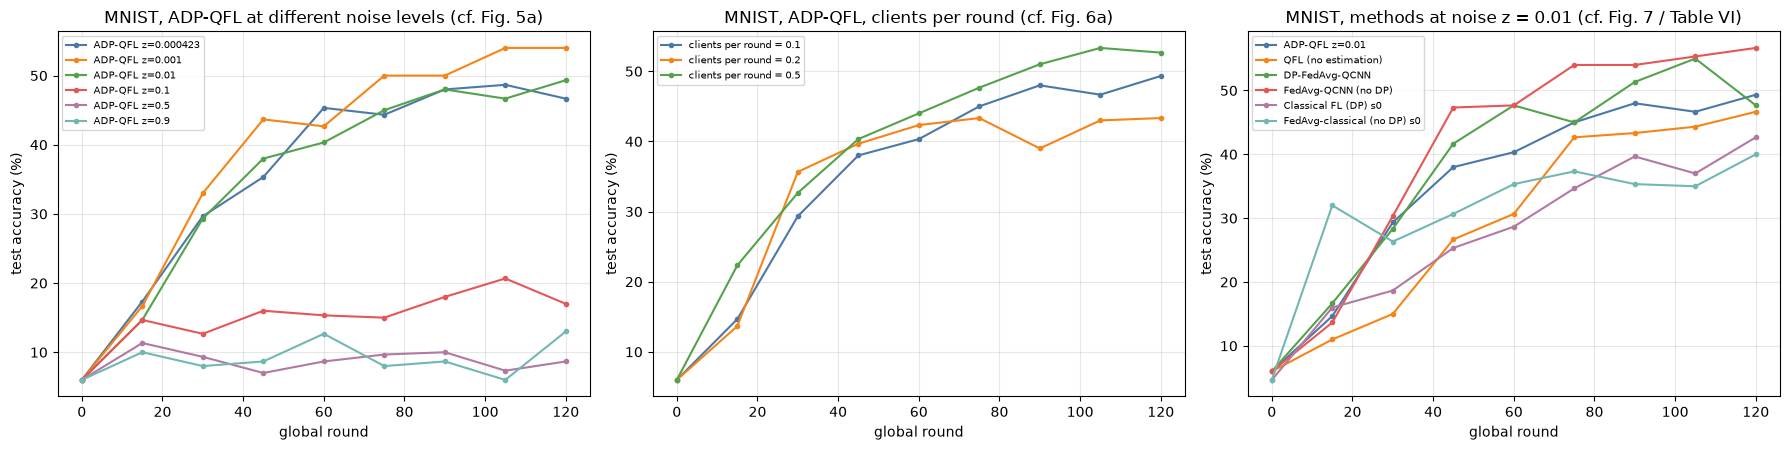

In [17]:
def curves(ax, RES, names, title, labels=None, ylim=None):
    for i, n in enumerate(names):
        if n not in RES: continue
        h = RES[n]["hist"]; ax.plot(h["round"], 100 * np.array(h["test_acc"]), marker="o", ms=3, color=PALETTE[i % 10], label=(labels or {}).get(n, n))
    ax.set_xlabel("global round"); ax.set_ylabel("test accuracy (%)"); ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    if ylim: ax.set_ylim(*ylim)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
curves(ax[0], RES_M, [f"ADP-QFL z={z:g}" for z in NOISE_RUN], "MNIST, ADP-QFL at different noise levels (cf. Fig. 5a)")
curves(ax[1], RES_M, [f"ADP-QFL z={Z_MAIN:g}"] + [f"ADP-QFL frac={f:g}" for f in FRACS_RUN if f != FRAC_MAIN], "MNIST, ADP-QFL, clients per round (cf. Fig. 6a)",
       labels={f"ADP-QFL z={Z_MAIN:g}": f"clients per round = {FRAC_MAIN:g}"} | {f"ADP-QFL frac={f:g}": f"clients per round = {f:g}" for f in FRACS_RUN})
curves(ax[2], RES_M, [f"ADP-QFL z={Z_MAIN:g}", "QFL (no estimation)", "DP-FedAvg-QCNN", "FedAvg-QCNN (no DP)", f"Classical FL (DP) s{CLASSICAL_SEEDS[0]}", f"FedAvg-classical (no DP) s{CLASSICAL_SEEDS[0]}"],
       f"MNIST, methods at noise z = {Z_MAIN:g} (cf. Fig. 7 / Table VI)")
plt.tight_layout(); plt.show()

In [18]:
# Table VI analogue: test accuracy at the same *fractions* of the run as the paper's rounds 100 / 300 / 600 / 800 of 800 (12.5 %, 37.5 %, 75 %, 100 %)
paper_vi = {"ADP-QFL": [0.83, 0.91, 0.94, 0.98], "QFL (no estimation)": [0.78, 0.85, 0.89, 0.90], "Classical FL (DP)": [0.72, 0.80, 0.84, 0.85]}
frac_pts = [100 / 800, 300 / 800, 600 / 800, 1.0]
mine = {"ADP-QFL": f"ADP-QFL z={Z_MAIN:g}", "QFL (no estimation)": "QFL (no estimation)", "Classical FL (DP)": f"Classical FL (DP) s{CLASSICAL_SEEDS[0]}"}
rows = []
for k, name in mine.items():
    h = RES_M[name]["hist"]
    rows.append({"method": k, "": "paper (rounds 100/300/600/800)", **{f"{int(f*100)} % of run": v for f, v in zip(frac_pts, paper_vi[k])}})
    rows.append({"method": k, "": f"notebook (rounds {', '.join(str(int(round(f * ROUNDS_MNIST))) for f in frac_pts)})", **{f"{int(f*100)} % of run": float(np.interp(f * ROUNDS_MNIST, h["round"], h["test_acc"])) for f in frac_pts}})
display(pd.DataFrame(rows).round(3))

,method,,12 % of run,37 % of run,75 % of run,100 % of run
0,ADP-QFL,paper (rounds 100/300/600/800),0.830,0.910,0.940,0.980
1,ADP-QFL,"notebook (rounds 15, 45, 90, 120)",0.147,0.380,0.480,0.493
2,QFL (no estimation),paper (rounds 100/300/600/800),0.780,0.850,0.890,0.900
3,QFL (no estimation),"notebook (rounds 15, 45, 90, 120)",0.110,0.267,0.433,0.467
4,Classical FL (DP),paper (rounds 100/300/600/800),0.720,0.800,0.840,0.850
5,Classical FL (DP),"notebook (rounds 15, 45, 90, 120)",0.160,0.253,0.397,0.427


## 5. CIFAR-10 experiments

The same pipeline on CIFAR-10 with the small convolutional encoder (fewer rounds because the encoder makes every step more expensive). Run: ADP-QFL at the main noise level, FedAvg-QCNN without DP, and the classical counterparts.
The participation-rate and noise-level sweeps are run on MNIST only (CPU budget).

Result in one line: after 50 rounds the QCNN runs are still at chance level (see the table) - the CIFAR-10 budget is far too small for an 8-qubit circuit behind a small encoder, so this section documents the pipeline and a null result rather than a test of the paper's 83.85 %.

--- cifar: model = qcnn, local = meta, 1 runs, 10 client trainings per round, 50 rounds
  round    0/50  ADP-QFL z=0.01=9.7%   [0s]


  round   30/50  ADP-QFL z=0.01=10.7%   [57s]


  round   50/50  ADP-QFL z=0.01=10.0%   [85s]


    group time 85s
--- cifar: model = qcnn, local = sgd, 1 runs, 10 client trainings per round, 50 rounds
  round    0/50  FedAvg-QCNN (no DP)=9.7%   [0s]


  round   30/50  FedAvg-QCNN (no DP)=10.7%   [30s]


...

  round    0/50  FedAvg-classical (no DP)=9.7%  Classical FL (DP)=9.7%   [0s]


  round   30/50  FedAvg-classical (no DP)=10.7%  Classical FL (DP)=18.7%   [33s]


  round   50/50  FedAvg-classical (no DP)=20.3%  Classical FL (DP)=11.3%   [58s]


    group time 58s
CIFAR-10 experiments done in 3.3 min


,run,model,update,clients/round,noise,z,estimation,final test acc (%),final train acc (%),best curve acc (%),mean accepted,mean sent fraction,mean ||update||
0,ADP-QFL z=0.01,qcnn,meta,10,adaptive,0.01,True,9.60,8.6,10.67,9.26,0.28,0.41
1,FedAvg-QCNN (no DP),qcnn,sgd,10,none,0.00,False,9.47,13.2,10.67,10.00,1.00,0.52
2,FedAvg-classical (no DP),classical,sgd,10,none,0.00,False,17.33,19.0,20.33,10.00,1.00,0.61
3,Classical FL (DP),classical,sgd,10,fixed,0.01,False,9.73,13.0,20.33,10.00,1.00,0.61


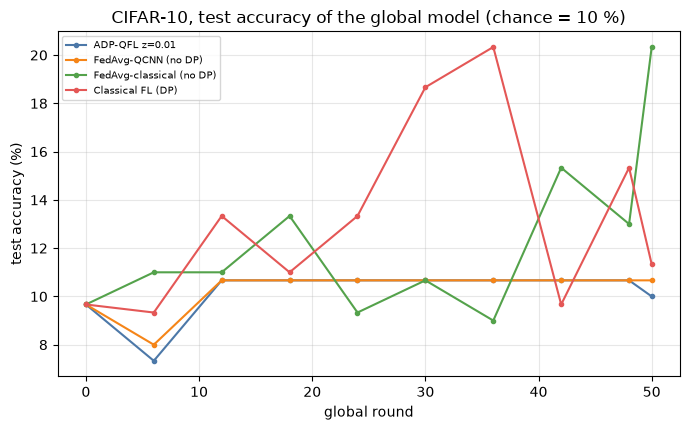

In [19]:
Ac = [mk(f"ADP-QFL z={Z_MAIN:g}", K_MAIN, "adaptive", Z_MAIN, True)]
Bc = [mk("FedAvg-QCNN (no DP)", K_MAIN, "none", 0.0, False, clip=False)]
Cc = [mk("FedAvg-classical (no DP)", K_MAIN, "none", 0.0, False, clip=False), mk("Classical FL (DP)", K_MAIN, "fixed", Z_MAIN, False)]
t_start = time.time()
RES_C = run_dataset("cifar", [("qcnn", "meta", Ac), ("qcnn", "sgd", Bc), ("classical", "sgd", Cc)], ROUNDS_CIFAR)
print(f"CIFAR-10 experiments done in {(time.time()-t_start)/60:.1f} min")
TAB_C = summary_table(RES_C)
display(TAB_C.drop(columns=["seconds"]))
fig, ax = plt.subplots(1, 1, figsize=(7, 4.4))
curves(ax, RES_C, list(RES_C), f"CIFAR-10, test accuracy of the global model (chance = 10 %)")
plt.tight_layout(); plt.show()

### Check of the first-order meta-gradient

The notebook uses `grad L(theta~; query)` (first-order) instead of the exact `(I - eta * Hessian_support(theta~)) grad L(theta~; query)` of Eq. 3-4. The cell computes both for the trained ADP-QFL global model on real client batches and reports their cosine similarity and relative difference.

In [20]:
def meta_gradient_check(model, theta, data, n_clients=8, seed=0):
    g = torch.Generator().manual_seed(seed); K = n_clients
    idx = torch.randperm(N_CLIENTS, generator=g)[:K]
    Xk, Yk = data["Xc"][idx], data["Yc"][idx]; ar = torch.arange(K)[:, None]
    perm = torch.argsort(torch.rand(K, Yk.shape[1], generator=g), 1)[:, :BATCH]; hb = BATCH // 2
    xs, ys, xq, yq = Xk[ar, perm[:, :hb]], Yk[ar, perm[:, :hb]], Xk[ar, perm[:, hb:]], Yk[ar, perm[:, hb:]]
    th = theta[None].expand(K, -1).clone().requires_grad_(True)
    gs = torch.autograd.grad(model.loss(th, xs, ys).sum(), th)[0]
    th_t = (th - META_ETA * gs).detach().requires_grad_(True)
    gq = torch.autograd.grad(model.loss(th_t, xq, yq).sum(), th_t)[0]
    gs2 = torch.autograd.grad(model.loss(th_t, xs, ys).sum(), th_t, create_graph=True)[0]
    hv = torch.autograd.grad((gs2 * gq.detach()).sum(), th_t)[0]
    exact = gq - META_ETA * hv
    cos = torch.nn.functional.cosine_similarity(exact, gq, dim=1)
    rel = (exact - gq).norm(dim=1) / exact.norm(dim=1)
    return float(cos.mean()), float(rel.mean())

mod_q = Model("mnist", "qcnn")
for label, theta in (("initial global model", mod_q.layout.init(np.random.default_rng(1000))), (f"trained ADP-QFL global model (z = {Z_MAIN:g})", RES_M[f"ADP-QFL z={Z_MAIN:g}"]["G"])):
    cos, rel = meta_gradient_check(mod_q, theta, DATA["mnist"])
    print(f"{label:48s}: cosine(first-order, exact second-order) = {cos:.4f} | mean ||exact - first-order|| / ||exact|| = {rel:.4f}")

initial global model                            : cosine(first-order, exact second-order) = 0.9481 | mean ||exact - first-order|| / ||exact|| = 0.3017


trained ADP-QFL global model (z = 0.01)         : cosine(first-order, exact second-order) = 0.9996 | mean ||exact - first-order|| / ||exact|| = 0.0247


## 6. Gradient variance: barren plateaus and the effect of the noise (Fig. 1, Theorem 1, Corollaries 1-3)

**Fig. 1 / Theorem 1.** The paper claims that the variance of the gradient of an n-qubit circuit falls exponentially with the number of qubits (Fig. 1a) and converges to a "2-design" limit with the number of layers (Fig. 1b).
The ansatz of Fig. 1 is not given, so the notebook uses the standard layered ansatz of McClean et al.: `RY` on every qubit followed by a ladder of `CZ`, random angles, and computes the **exact** variance (over random initialisations) of the derivative of the
first rotation angle, by the parameter-shift rule on an exact state-vector simulation (a NumPy simulator, checked against PennyLane for a small circuit). Two costs are used: the global cost `<Z x ... x Z>` and the local cost `<Z_0 Z_1>`.
The cell also measures the same quantity for the 8-qubit **QCNN** of this notebook (cost `<Z_7>`), for which no barren plateau is expected, and compares the variance of the clients' *updates* with the variance of the injected noise.

In [21]:
def hea_costs(angles, n, depth_marks, cost):
    """Layered hardware-efficient ansatz (RY on every qubit, then CZ on neighbours), exact state-vector simulation of S random circuits at once.
    angles: (S, L, n). Returns {L': cost value (S,)} for every prefix depth L' in depth_marks. cost = 'local' (<Z0 Z1>) or 'global' (<Z x ... x Z>)."""
    S, L, _ = angles.shape
    st = np.zeros((S, 2 ** n)); st[:, 0] = 1.0
    idx = np.arange(2 ** n)
    bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1                  # qubit 0 = most significant bit
    cz = np.ones(2 ** n)
    for q in range(n - 1): cz *= 1 - 2 * (bits[:, q] & bits[:, q + 1])            # product of CZ(q, q+1)
    zsign = 1 - 2 * bits
    obs = zsign[:, 0] * zsign[:, 1] if cost == "local" else np.prod(zsign, axis=1)
    out = {}
    for l in range(L):
        c, s = np.cos(angles[:, l] / 2), np.sin(angles[:, l] / 2)                  # (S, n)
        for q in range(n):
            v = st.reshape(S, 2 ** q, 2, -1)
            a0, a1 = v[:, :, 0, :], v[:, :, 1, :]
            cq, sq = c[:, q][:, None, None], s[:, q][:, None, None]
            st = np.stack([cq * a0 - sq * a1, sq * a0 + cq * a1], axis=2).reshape(S, -1)
        st = st * cz
        if (l + 1) in depth_marks: out[l + 1] = (st ** 2) @ obs
    return out

def grad_variance(n, depth_marks, S, cost, rng):
    """Variance over random initialisations of dC/dtheta for the first rotation (parameter-shift rule, exact)."""
    L = max(depth_marks)
    a = rng.uniform(0, 2 * np.pi, size=(S, L, n))
    ap, am = a.copy(), a.copy(); ap[:, 0, 0] += np.pi / 2; am[:, 0, 0] -= np.pi / 2
    cp, cm = hea_costs(ap, n, depth_marks, cost), hea_costs(am, n, depth_marks, cost)
    return {l: float(np.var((cp[l] - cm[l]) / 2)) for l in depth_marks}

# ---- sanity check of the NumPy simulator against PennyLane for a small circuit ----
_n, _L = 3, 2
_a = np.random.default_rng(1).uniform(0, 2 * np.pi, size=(1, _L, _n))
_dev = qml.device("default.qubit", wires=_n)
@qml.qnode(_dev)
def _hea(a):
    for l in range(_L):
        for q in range(_n): qml.RY(a[l, q], wires=q)
        for q in range(_n - 1): qml.CZ(wires=[q, q + 1])
    return qml.expval(qml.PauliZ(0) @ qml.PauliZ(1))
print("NumPy HEA simulator vs PennyLane:", float(hea_costs(_a, _n, [_L], "local")[_L][0]), "vs", float(_hea(_a[0])))
assert abs(float(hea_costs(_a, _n, [_L], "local")[_L][0]) - float(_hea(_a[0]))) < 1e-10

NumPy HEA simulator vs PennyLane: 0.515829913597463 vs 0.515829913597463


gradient-variance study done in 29s (150 random circuits per point)


QCNN-8, random initialisation: median over the 64 parameters of Var[d<Z_7> (last active qubit)/d theta] = 0.0041


QCNN-8, random initialisation: median over the 64 parameters of Var[d<Z_0> (a pooled-away qubit)/d theta] = 0.0000
reference, 8 qubits layered RY+CZ, local cost, 100 layers: 0.0208; global cost: 0.00487


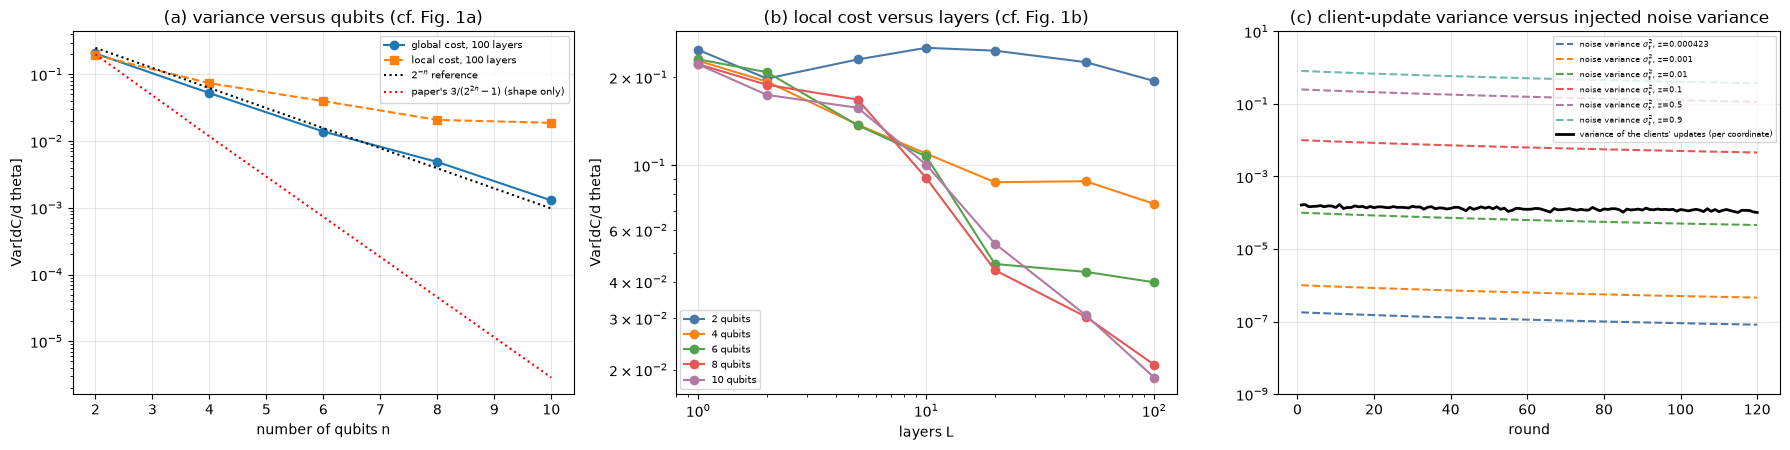

global cost: log2 Var falls by 0.90 per added qubit (R^2 = 0.998); a pure 2^-n law would give 1.00, the bound shape 3/(2^2n-1) gives 2.00
local cost, Var(L=100) / Var(L=50) per qubit count: {2: np.float64(0.86), 4: np.float64(0.84), 6: np.float64(0.92), 8: np.float64(0.68), 10: np.float64(0.61)}


In [22]:
rng_gv = np.random.default_rng(SEED)
t0 = time.time()
GV = {cost: {n: grad_variance(n, GV_DEPTHS, GV_SAMPLES, cost, rng_gv) for n in GV_QUBITS} for cost in ("global", "local")}
print(f"gradient-variance study done in {time.time()-t0:.0f}s ({GV_SAMPLES} random circuits per point)")

Lmax = max(GV_DEPTHS)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ns = np.array(GV_QUBITS)
for cost, st in (("global", "o-"), ("local", "s--")):
    ax[0].semilogy(ns, [GV[cost][n][Lmax] for n in ns], st, label=f"{cost} cost, {Lmax} layers")
ax[0].semilogy(ns, 0.25 * 2.0 ** (-(ns - 2)), "k:", label="$2^{-n}$ reference"); ax[0].semilogy(ns, 3.0 / (4.0 ** ns - 1), "r:", label="paper's $3/(2^{2n}-1)$ (shape only)")
ax[0].set_xlabel("number of qubits n"); ax[0].set_ylabel("Var[dC/d theta]"); ax[0].set_title("(a) variance versus qubits (cf. Fig. 1a)"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
for i, n in enumerate(GV_QUBITS):
    ax[1].loglog(GV_DEPTHS, [GV["local"][n][L] for L in GV_DEPTHS], "o-", color=PALETTE[i], label=f"{n} qubits")
ax[1].set_xlabel("layers L"); ax[1].set_ylabel("Var[dC/d theta]"); ax[1].set_title("(b) local cost versus layers (cf. Fig. 1b)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)

# ---- the 8-qubit QCNN of this notebook: gradient variance over random initialisations, and variance of the clients' updates versus injected noise ----
S = 400; g_ = torch.Generator().manual_seed(SEED)
ang_q = (torch.rand(S, 1, NQ, generator=g_, dtype=torch.float64) * 2 - 1) * math.pi
circ_q = (torch.rand(S, N_CIRC, generator=g_, dtype=torch.float64) * 2 * math.pi).requires_grad_(True)
out_q = qcnn_expvals(ang_q, circ_q)[:, 0, :]
var_qcnn = {}
for q_, lbl in ((7, "<Z_7> (last active qubit)"), (0, "<Z_0> (a pooled-away qubit)")):
    gq_ = torch.autograd.grad(out_q[:, q_].sum(), circ_q, retain_graph=True)[0]
    var_qcnn[lbl] = float(gq_.var(0).median())
    print(f"QCNN-8, random initialisation: median over the 64 parameters of Var[d{lbl}/d theta] = {var_qcnn[lbl]:.4f}")
print(f"reference, 8 qubits layered RY+CZ, local cost, {Lmax} layers: {GV['local'][8][Lmax]:.4f}; global cost: {GV['global'][8][Lmax]:.5f}")

for i, z in enumerate(NOISE_RUN):
    h = RES_M[f"ADP-QFL z={z:g}"]["hist"]
    ax[2].semilogy(np.arange(1, len(h["update_var"]) + 1), np.array(h["sigma"]) ** 2 + 1e-12, "--", color=PALETTE[i], label=f"noise variance $\\sigma_t^2$, z={z:g}")
h0 = RES_M[f"ADP-QFL z={Z_MAIN:g}"]["hist"]
ax[2].semilogy(np.arange(1, len(h0["update_var"]) + 1), h0["update_var"], "k-", lw=2, label="variance of the clients' updates (per coordinate)")
ax[2].set_ylim(1e-9, 10); ax[2].set_xlabel("round"); ax[2].set_title("(c) client-update variance versus injected noise variance"); ax[2].legend(fontsize=6); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

gl = [GV["global"][n][Lmax] for n in GV_QUBITS]
slope, intercept = np.polyfit(GV_QUBITS, np.log2(gl), 1)
pred = slope * np.array(GV_QUBITS) + intercept; r2 = 1 - np.sum((np.log2(gl) - pred) ** 2) / np.sum((np.log2(gl) - np.mean(np.log2(gl))) ** 2)
print(f"global cost: log2 Var falls by {-slope:.2f} per added qubit (R^2 = {r2:.3f}); a pure 2^-n law would give 1.00, the bound shape 3/(2^2n-1) gives 2.00")
sat = [GV["local"][n][Lmax] / GV["local"][n][GV_DEPTHS[-2]] for n in GV_QUBITS]
print("local cost, Var(L=%d) / Var(L=%d) per qubit count:" % (Lmax, GV_DEPTHS[-2]), dict(zip(GV_QUBITS, np.round(sat, 2))))

## 7. What privacy do these noise levels actually give?

The paper calls the values 0.000423 ... 0.9 both "noise levels" and "privacy budgets epsilon". Taken literally as epsilon in Lemma 1 (`sigma^2 = 8 T (2L + b)^2 log(1/delta) / (K^2 epsilon^2)`, `T = 800`, `K = 10`, `delta = 1e-5`) they would require absurdly large noise,
and a noise std of 0.9 per coordinate cannot leave 97.6 % accuracy. The notebook therefore uses them as the **noise multiplier** `z` and asks what `(epsilon, delta)` that gives. The accountant below is the standard Renyi-DP accountant of the sampled Gaussian mechanism
(Mironov et al. 2019, integer orders): per round a client set of `K` out of `N` is sampled (`q = K / N`), every update is clipped to `C`, the server averages `K` noisy updates, so the noise multiplier seen by the mean is `z_eff = z * sqrt(K)` (trusted-server, client-level, add/remove adjacency).
Rounds compose by adding Renyi divergences; the decaying noise of ADP-QFL is accounted round by round. The data-dependent sparse support of the estimate is **not** accounted, so the epsilon for ADP-QFL is a lower bound.

In [23]:
from scipy.special import gammaln, logsumexp
ALPHAS = np.arange(2, 257)

_A = ALPHAS[:, None].astype(float); _K = np.arange(ALPHAS.max() + 1)[None, :].astype(float); _MASK = _K <= _A
_LOGC = gammaln(_A + 1) - gammaln(_K + 1) - gammaln(np.where(_MASK, _A - _K, 0) + 1)       # log binomial(alpha, k), one row per order alpha

def rdp_sampled_gaussian(q, z):
    """Renyi-DP of the Poisson-subsampled Gaussian mechanism at the integer orders ALPHAS (Mironov, Talwar, Zhang 2019); z = noise multiplier (std / sensitivity)."""
    logt = _LOGC + np.where(_MASK, _A - _K, 0) * np.log1p(-q) + _K * np.log(q) + (_K * _K - _K) / (2 * z * z)
    return logsumexp(np.where(_MASK, logt, -np.inf), axis=1) / (ALPHAS - 1)

def epsilon(z_per_round, q, delta=DELTA):
    """z_per_round: effective noise multiplier of every round (array). Returns epsilon after composing all rounds."""
    lz = np.round(np.log(np.asarray(z_per_round)) * 100) / 100                       # group rounds with (almost) the same noise: 0.5 % resolution in z, rounded conservatively below
    vals, counts = np.unique(lz, return_counts=True)
    total = sum(c * rdp_sampled_gaussian(q, float(np.exp(v))) for v, c in zip(vals, counts))
    eps = total + np.log(1 / delta) / (ALPHAS - 1)
    return float(eps.min())

def eps_schedule(z, K, T, adaptive, q=None):
    q = q or K / N_CLIENTS
    zt = z / np.sqrt(1 + ALPHA_DECAY * np.arange(T)) if adaptive else np.full(T, z)
    return epsilon(zt * np.sqrt(K), q)

# validation of the accountant on a published case: TensorFlow-Privacy MNIST tutorial (q = 256/60000, z = 1.1, 60 epochs, delta = 1e-5) reports epsilon = 3.01
_chk = (rdp_sampled_gaussian(256 / 60000, 1.1) * (60 * 60000 // 256) + np.log(1 / DELTA) / (ALPHAS - 1)).min()
print(f"accountant check: epsilon = {_chk:.2f} (published: 3.01)"); assert abs(_chk - 3.01) < 0.05

rows = []
for z in NOISE_LEVELS:
    rows.append({"noise multiplier z": z, "eps, adaptive noise, this run's rounds": eps_schedule(z, K_MAIN, ROUNDS_MNIST, True),
                 "eps, adaptive noise, 800 rounds (paper)": eps_schedule(z, K_MAIN, PAPER_ROUNDS, True), "eps, fixed noise, 800 rounds": eps_schedule(z, K_MAIN, PAPER_ROUNDS, False)})
TAB_EPS = pd.DataFrame(rows); pd.options.display.float_format = "{:.4g}".format
display(TAB_EPS)

# noise needed for epsilon = 1 at the paper's schedule, and the value printed Lemma 1 would demand
lo, hi = 0.01, 50.0
for _ in range(40):
    mid = math.sqrt(lo * hi)
    if eps_schedule(mid, K_MAIN, PAPER_ROUNDS, False) > 1.0: lo = mid
    else: hi = mid
Z_FOR_EPS1 = hi
L_lip, b_est = CLIP_C, EST_REL_ERR * CLIP_C
sigma_lemma1 = math.sqrt(8 * PAPER_ROUNDS * (2 * L_lip + b_est) ** 2 * math.log(1 / DELTA)) / (K_MAIN * 1.0)
print(f"fixed noise, T = {PAPER_ROUNDS}, K = {K_MAIN}, q = {K_MAIN/N_CLIENTS:g}: epsilon = 1 (delta = {DELTA:g}) needs a noise multiplier z = {Z_FOR_EPS1:.3f} (z_eff = {Z_FOR_EPS1*math.sqrt(K_MAIN):.2f})")
print(f"Lemma 1 as printed (L = C = {L_lip:g}, b = {b_est:g}, epsilon = 1, T = {PAPER_ROUNDS}, K = {K_MAIN}): sigma = {sigma_lemma1:.1f} per coordinate, i.e. z = {sigma_lemma1/CLIP_C:.1f} (updates of norm <= {CLIP_C:g})")

accountant check: epsilon = 3.01 (published: 3.01)


,noise multiplier z,"eps, adaptive noise, this run's rounds","eps, adaptive noise, 800 rounds (paper)","eps, fixed noise, 800 rounds"
0,0.000423,1.07e+08,2.233e+09,4.499e+08
1,0.001,1.915e+07,3.996e+08,8.056e+07
2,0.1,1373,3.629e+04,4310
3,0.5,6.661,84.65,11.92
4,0.9,2.854,18.67,5.581


fixed noise, T = 800, K = 10, q = 0.1: epsilon = 1 (delta = 1e-05) needs a noise multiplier z = 4.409 (z_eff = 13.94)
Lemma 1 as printed (L = C = 1, b = 0.3, epsilon = 1, T = 800, K = 10): sigma = 62.4 per coordinate, i.e. z = 62.4 (updates of norm <= 1)


## 8. Paper versus this notebook

The table puts every checkable number of the paper next to the notebook's. Verdicts: **reproduced** (within 2 accuracy points of the paper, or the qualitative statement holds), **not reached** / **exceeded** (with the gap), **not supported** (the statement is tested and fails),
**cannot be checked** (no experiment of that kind is possible here). The notebook's accuracies are for a federation that uses about 6 % of the paper's local gradient steps and 8 % of its MNIST images (see the table of choices), so the absolute accuracies cannot be expected to match;
the comparisons *between methods inside the notebook* are what the scaled-down setting can test.

In [24]:
def pct(x): return None if x is None else 100.0 * x
def get(RES, name, key="final_test"): return RES[name][key] if name in RES else None
def acc_verdict(paper, nb, tol=2.0):
    if nb is None: return "cannot be checked (run not executed)"
    d = nb - paper
    return "reproduced" if abs(d) <= tol else (f"not reached ({d:+.1f} pts)" if d < 0 else f"exceeded ({d:+.1f} pts)")
def fmt(x, nd=1): return "-" if x is None else (f"{x:.{nd}f}" if isinstance(x, (float, int, np.floating)) else str(x))

main = f"ADP-QFL z={Z_MAIN:g}"
def seed_mean(RES, base):
    """Mean final test accuracy (%) over the seeds of a headline run (names: base, base + ' s1', ...)."""
    v = [100 * RES[n]["final_test"] for n in [base] + [f"{base} s{sd}" for sd in MAIN_SEEDS[1:]] if n in RES]
    return float(np.mean(v)) if v else None
adp_m, fa_m, dpfa_m = seed_mean(RES_M, main), seed_mean(RES_M, "FedAvg-QCNN (no DP)"), seed_mean(RES_M, "DP-FedAvg-QCNN")
noest_m = seed_mean(RES_M, "QFL (no estimation)")
HEAD = pd.DataFrame([{"method": b, "seeds": len(MAIN_SEEDS), **{f"seed {sd}": 100 * RES_M[(b if sd == 0 else f"{b} s{sd}")]["final_test"] for sd in MAIN_SEEDS}, "mean": seed_mean(RES_M, b)}
                     for b in (main, "QFL (no estimation)", "DP-FedAvg-QCNN", "FedAvg-QCNN (no DP)")]).round(1)
print("final test accuracy (%) of the headline quantum runs per federation seed:"); display(HEAD)
cl_dp_m = float(np.mean([100 * RES_M[f"Classical FL (DP) s{s}"]["final_test"] for s in CLASSICAL_SEEDS]))
cl_fa_m = float(np.mean([100 * RES_M[f"FedAvg-classical (no DP) s{s}"]["final_test"] for s in CLASSICAL_SEEDS]))
adp_c, fa_c = pct(get(RES_C, main)), pct(get(RES_C, "FedAvg-QCNN (no DP)"))
levels = {z: pct(get(RES_M, f"ADP-QFL z={z:g}")) for z in NOISE_RUN if z in NOISE_LEVELS}          # the paper's own noise levels
fr = {f: (100 * RES_M[main]["final_test"] if f == FRAC_MAIN else pct(get(RES_M, f"ADP-QFL frac={f:g}"))) for f in FRACS_RUN}       # same seed (0) for all participation rates

rows = []
def add(claim, paper, nb, verdict, note=""): rows.append({"claim": claim, "paper": paper, "notebook": nb, "verdict": verdict, "note": note})

add("Table IV, MNIST, ADP-QFL accuracy (%)", 98.47, fmt(adp_m), acc_verdict(98.47, adp_m), f"{ROUNDS_MNIST} rounds, {N_PER_CLIENT} images/client, noise z={Z_MAIN:g}, mean of {len(MAIN_SEEDS)} seed(s), final test acc on {FINAL_TEST} images")
d_fa = None if (adp_m is None or fa_m is None) else adp_m - fa_m
add("Table IV, MNIST, ADP-QFL minus FedAvg (pts)", "+0.31", fmt(d_fa), "cannot be checked" if d_fa is None else acc_verdict(0.31, d_fa), "FedAvg-QCNN without DP, same budget")
d_dp = None if (adp_m is None or dpfa_m is None) else adp_m - dpfa_m
add("MNIST, ADP-QFL minus DP-FedAvg-QCNN (pts), fair private baseline", "n/a", fmt(d_dp), "-" if d_dp is None else ("ADP-QFL better" if d_dp > 1 else ("ADP-QFL worse" if d_dp < -1 else "no difference (within 1 pt)")), "same clipping and noise level, fixed instead of adaptive noise, no meta update, no estimation")
add("Table IV, CIFAR-10, ADP-QFL accuracy (%)", 83.85, fmt(adp_c), acc_verdict(83.85, adp_c), f"{ROUNDS_CIFAR} rounds; chance level is 10 %; an 8-qubit, 64-parameter circuit behind a small CNN encoder")
d_c = None if (adp_c is None or fa_c is None) else adp_c - fa_c
add("Table IV, CIFAR-10, ADP-QFL minus FedAvg (pts)", f"{83.85-56.91:+.1f}", fmt(d_c), "cannot be checked" if d_c is None else acc_verdict(83.85 - 56.91, d_c), "both runs are near chance level here; the paper's FedAvg is a different (classical) model")
add("Table IV, FedBN / pFedMe / FedRep / FedQNN accuracies and training times", "see Table IV", "-", "cannot be checked", "personalised methods not re-implemented; times are machine dependent")
add("Table V, paired t-tests", "p < 0.05", "-", "cannot be checked", "needs repeated full-scale runs")
lv = [v for v in levels.values() if v is not None]
add("Fig. 5a, MNIST accuracy above 97.57 % for every noise level", "> 97.57", f"min {fmt(min(lv))} / max {fmt(max(lv))}", "reproduced" if min(lv) > 97.57 - 2 else f"not reached ({min(lv)-97.57:+.1f} pts at the worst level)", "per level: " + ", ".join(f"z={z:g}: {fmt(v)}" for z, v in levels.items()))
add("Fig. 5a, accuracy insensitive to the noise level (spread over levels)", "~0.9 pts", f"{fmt(max(lv)-min(lv))} pts", "reproduced" if max(lv) - min(lv) <= 2 else "not reproduced", "spread = best minus worst final accuracy over the noise levels run")
add("Fig. 5b, CIFAR-10 accuracy 83.96 % under all noise levels", 83.96, "-", "cannot be checked", "noise sweep run on MNIST only")
fv = [v for v in fr.values() if v is not None]
add("Fig. 6a, MNIST stable over 10 / 20 / 50 % participation (spread)", "~ 1-2 pts", f"{fmt(max(fv)-min(fv))} pts", "reproduced" if max(fv) - min(fv) <= 2 else "not reproduced", "per rate: " + ", ".join(f"{f:g}: {fmt(v)}" for f, v in fr.items()))
add("Fig. 6b, CIFAR-10 rises with participation 82.78 / 82.98 / 83.85", "82.78 / 82.98 / 83.85", "-", "cannot be checked", "participation sweep run on MNIST only")
add("Table VI, ADP-QFL final accuracy (%)", 98.0, fmt(adp_m), acc_verdict(98.0, adp_m), "same run as above")
add("Table VI, QFL (no estimation) final accuracy (%)", 90.0, fmt(noest_m), acc_verdict(90.0, noest_m), "ADP-QFL minus sparse estimate / consensus filter")
add("Table VI, Classical FL (DP) final accuracy (%)", 85.0, fmt(cl_dp_m), acc_verdict(85.0, cl_dp_m), f"mean of {len(CLASSICAL_SEEDS)} seed(s)")
order_ok = None if (adp_m is None or noest_m is None) else (adp_m - noest_m >= 2 and noest_m - cl_dp_m >= 2)
order_sorted = None if (adp_m is None or noest_m is None) else (adp_m > noest_m > cl_dp_m)
add("Table VI ordering ADP-QFL > QFL (no estimation) > Classical FL (DP)", "0.98 > 0.90 > 0.85", f"{fmt(adp_m)} / {fmt(noest_m)} / {fmt(cl_dp_m)}", "-" if order_ok is None else ("reproduced" if order_ok else ("not resolved: order holds but gaps < 2 pts, within seed noise" if order_sorted else "not reproduced")), f"{len(MAIN_SEEDS)} seed(s) for the quantum runs (seed-to-seed spread is several points, see the table above)")
add("Model estimation helps (ADP-QFL minus QFL without estimation, pts)", "+8", fmt(None if (adp_m is None or noest_m is None) else adp_m - noest_m), "-" if order_ok is None else acc_verdict(8.0, adp_m - noest_m, tol=2.0), "")
sent = float(np.mean(RES_M[main]["hist"]["comm"])); accd = float(np.mean(RES_M[main]["hist"]["accepted"]))
add("Sparse estimation reduces communication", "qualitative", f"{100*sent:.0f} % of the coordinates sent, {accd:.1f}/{K_MAIN} clients accepted per round", "reproduced (mechanism works)", "no number is given in the paper; the saving is by construction of the error bound")
add("Fig. 1a / Theorem 1: variance falls exponentially with the number of qubits", "qualitative", f"log2 Var falls by {-slope:.2f} per qubit, R^2 = {r2:.2f} (global cost)", "reproduced" if (slope < -0.5 and r2 > 0.9) else "not reproduced", "ansatz and cost of Fig. 1 are not given; exact values of Theorem 1 need the constant sigma^2, so only the trend is checkable")
add("Fig. 1b: variance converges to a 2-design limit with the number of layers", "qualitative", "Var(L=%d)/Var(L=%d) = %s" % (Lmax, GV_DEPTHS[-2], ", ".join(f"{n}q: {s:.2f}" for n, s in zip(GV_QUBITS, sat))), "reproduced" if all(0.75 < s < 1.33 for s in sat) else "partly (small circuits saturate, larger ones are still decreasing)", "local cost; global cost is flat from the first layers")
if RES_M and len(NOISE_RUN) > 1:
    zlo, zhi = min(NOISE_RUN), Z_MAIN
    benefit = 100 * RES_M[f"ADP-QFL z={zhi:g}"]["final_test"] - 100 * RES_M[f"ADP-QFL z={zlo:g}"]["final_test"]
    add("Corollaries 2-3: added noise helps convergence (accuracy at z=%g minus z=%g)" % (zhi, zlo), "noise helps", fmt(benefit) + " pts", "supported" if benefit > 1 else "not supported", "the injected noise is the only difference between the two runs")
add("Strong privacy protection at these noise levels", "epsilon = 1, delta = 1e-5", "eps(z=%g, 800 rounds) = %s" % (Z_MAIN, f"{eps_schedule(Z_MAIN, K_MAIN, PAPER_ROUNDS, True):.3g}"), "not supported" if eps_schedule(Z_MAIN, K_MAIN, PAPER_ROUNDS, True) > 10 else "supported", "noise multiplier needed for epsilon = 1 with fixed noise: z = %.2f" % Z_FOR_EPS1)
add("Mitigation of intermediate quantum (device) noise", "claimed", "-", "cannot be checked", "Section VI reports no device-noise experiment; this notebook simulates ideal circuits")
VERDICTS = pd.DataFrame(rows)
display(VERDICTS)

final test accuracy (%) of the headline quantum runs per federation seed:


,method,seeds,seed 0,seed 1,mean
0,ADP-QFL z=0.01,2,46.2,40.1,43.1
1,QFL (no estimation),2,47.2,37.3,42.2
2,DP-FedAvg-QCNN,2,49.6,50.3,50
3,FedAvg-QCNN (no DP),2,57.3,58.3,57.8


,claim,paper,notebook,verdict,note
0,"Table IV, MNIST, ADP-QFL accuracy (%)",98.47,43.1,not reached (-55.3 pts),"120 rounds, 50 images/client, noise z=0.01, mean of 2 seed(s), final test ac..."
1,"Table IV, MNIST, ADP-QFL minus FedAvg (pts)",+0.31,-14.7,not reached (-15.0 pts),"FedAvg-QCNN without DP, same budget"
2,"MNIST, ADP-QFL minus DP-FedAvg-QCNN (pts), fair private baseline",n/a,-6.8,ADP-QFL worse,"same clipping and noise level, fixed instead of adaptive noise, no meta upda..."
3,"Table IV, CIFAR-10, ADP-QFL accuracy (%)",83.85,9.6,not reached (-74.2 pts),"50 rounds; chance level is 10 %; an 8-qubit, 64-parameter circuit behind a s..."
4,"Table IV, CIFAR-10, ADP-QFL minus FedAvg (pts)",+26.9,0.1,not reached (-26.8 pts),both runs are near chance level here; the paper's FedAvg is a different (cla...
5,"Table IV, FedBN / pFedMe / FedRep / FedQNN accuracies and training times",see Table IV,-,cannot be checked,personalised methods not re-implemented; times are machine dependent
6,"Table V, paired t-tests",p < 0.05,-,cannot be checked,needs repeated full-scale runs
7,"Fig. 5a, MNIST accuracy above 97.57 % for every noise level",> 97.57,min 8.9 / max 49.1,not reached (-88.7 pts at the worst level),"per level: z=0.000423: 48.1, z=0.001: 49.1, z=0.1: 16.4, z=0.5: 8.9, z=0.9: ..."
8,"Fig. 5a, accuracy insensitive to the noise level (spread over levels)",~0.9 pts,40.3 pts,not reproduced,spread = best minus worst final accuracy over the noise levels run
9,"Fig. 5b, CIFAR-10 accuracy 83.96 % under all noise levels",83.96,-,cannot be checked,noise sweep run on MNIST only


## 9. Reading the paper critically

**What the run shows** (120 rounds, 100 clients x 50 images, MNIST; numbers from the tables above, final test accuracy, two seeds for the headline quantum runs).

1. **Scale.** The notebook uses about 5 % of the paper's local gradient steps and 8 % of its MNIST images. Even the non-private FedAvg-QCNN reaches only 57.8 % (57.3 / 58.3), the classical control 45.0 % (three seeds), so no absolute number of Table IV (98.47 / 83.85 %) is reached. CIFAR-10 is at chance level for the QCNN runs (9.6 and 9.5 %; the classical control reaches 17.3 %) after 50 rounds, so the CIFAR-10 claims are neither confirmed nor contradicted. What the shortened setting *can* test are the comparisons between methods and the mechanisms.
2. **Noise levels (Fig. 5).** With the noise read as a multiplier `z` on a unit clip norm, ADP-QFL trains for `z <= 0.01` (46 - 49 %), is badly hurt at `z = 0.1` (16.4 %) and sits at chance for `z = 0.5` and `0.9` (8.9 %, 11.1 %). The paper's statement that accuracy stays above 97.57 % for all five levels with *no* tuning cannot hold for any noise of this size: Fig. 6c shows why - the variance of the clients' updates is about 1e-4 per coordinate, the injected variance is 1e-4 at `z = 0.01` but 1e-2 at `z = 0.1` and 0.8 at `z = 0.9`. The five numbers must mean something else than a per-coordinate standard deviation on the transmitted update (the paper uses them both as "noise" and as "epsilon"), and the paper does not say what.
3. **Privacy.** The accountant (validated against the published TensorFlow-Privacy value 3.01) gives epsilon = 4e8 for `z = 0.001` and 3.6e4 for `z = 0.1` after 800 rounds with the paper's decaying noise, and still epsilon = 18.7 for `z = 0.9`; epsilon = 1 needs `z = 4.4` with fixed noise, and Lemma 1 as printed needs sigma = 62 per coordinate for updates of norm 1. The "strong privacy protection while maintaining 98 % accuracy" is therefore not supported by anything shown. The decaying noise `sigma_t^2 = sigma_0^2 / (1 + alpha t)` is, in addition, *costlier* in privacy than fixed noise (epsilon 18.7 versus 5.6 at `z = 0.9`): the later rounds are the ones that spend the budget. The data-dependent sparse support of the estimate is not accounted for in any of these numbers.
4. **Does ADP-QFL beat its comparison methods?** No resolvable advantage was found. At the same noise (`z = 0.01`): ADP-QFL 43.1 %, QFL without estimation 42.2 %, DP-FedAvg-QCNN 50.0 %, classical FL with DP 42.0 % (the seed-to-seed spread of a single run is 3 - 10 points, ADP-QFL: 46.2 / 40.1). The paper's gaps (98 / 90 / 85 %) are not reproduced; the ordering ADP > no estimation > classical DP holds numerically but with gaps below the noise. The meta-learning update with a 5 + 5 split of each mini-batch did not help (ADP-QFL is 6.8 points behind DP-FedAvg-QCNN, which has the same noise but more samples per gradient). The sparse estimate does what it promises (51 % of the coordinates sent for a relative error of 0.3) without a visible accuracy cost, but the consensus filter never rejected a client on MNIST (10.0 of 10 accepted), so "model selection" is inactive in this setting. The exact second-order meta-gradient is almost parallel to the first-order one used here (cosine 0.9996 for the trained model, 0.948 at initialisation).
5. **Quantum versus classical.** With the same encoder and read-out, the QCNN (FedAvg, 57.8 %) beats the 64-parameter classical control (45.0 %) by about 13 points; this is the one robust difference of the study, but the control (an 8 x 8 `tanh` layer) is deliberately minimal and the paper does not make this comparison. With DP noise the two are indistinguishable (43 versus 42 %).
6. **Barren plateaus (Fig. 1, Theorem 1, Corollaries).** The exponential decay of the gradient variance with the number of qubits is reproduced (global cost: log2 Var falls by 0.90 per qubit, R^2 = 1.00; a plain `2^-n` law), and local-cost variance saturates with depth for up to six qubits but is still falling for 8 - 10. The bound shape `3 / (2^(2n) - 1)` of Theorem 1 falls twice as fast, but it bounds a different quantity (the deviation of a mini-batch gradient estimate) with an unspecified constant `sigma^2`, so it cannot be checked. More importantly, the **QCNN used here has no barren plateau** (Var of d<Z_7>/d theta is 0.004 at random initialisation, comparable to the 8-qubit local-cost ansatz); the motivation that injected noise must rescue vanishing gradient variance does not apply to this architecture, and adding noise did not help (z = 0.01 versus 0.000423: -1.9 points).

**Where the paper is inconsistent or silent.** Noise enters the gradient in Eq. 4 but the transmitted parameters in Section IV-C; the symbol epsilon denotes both a privacy budget (0.000423 ... 0.9, Fig. 5) and the target of Lemma 1 (epsilon = 1, Table VI); the input encoding of the 8-qubit circuit, the classical layers (CIFAR-10 at 83.85 % with 8 qubits and 64 parameters cannot come from the circuit), the non-IID partition, the threshold `b * lambda`, the Lipschitz constant `L` of Lemma 1, the baselines' models and the repeated runs behind the t-tests of Table V are not given, and no code is released. Table VI quotes accuracies of 0.83 ... 0.98 under epsilon = 1 although Lemma 1 (and the accountant) require orders of magnitude more noise than Fig. 5 shows to be harmless.

**What would be needed to test the headline claims properly:** the paper's full budget (800 rounds x 600 images per client), an encoder specification, a statement of what the noise levels mean, and several seeds per cell - roughly 20 times the compute of this notebook, which is why the full-scale numbers are left as "not reached" rather than "contradicted".

## 10. Exercises

1. **Noise scale.** Rerun the noise sweep with `CLIP_C = 0.3` and with `CLIP_C = 3`. How does the accuracy at `z = 0.1` change, and why does the privacy accountant's epsilon not change when only `CLIP_C` is changed?
2. **Decay rate.** Vary `ALPHA_DECAY` in {0, 0.01, 0.1, 1}. The accountant says decaying noise costs privacy: plot accuracy against the final epsilon for the four values and decide whether the decay is worth it.
3. **Estimation threshold.** Sweep `EST_REL_ERR` in {0.1, 0.3, 0.5, 0.8} and `SEL_KAPPA` in {1.2, 2, 5}. Plot accuracy against the fraction of coordinates sent. Is there a setting that gives the communication saving for free?
4. **Hessian term.** Set `second_order=True` in `local_training` and compare with the first-order update on a few rounds. Is the extra CPU time justified, given the cosine similarity printed in section 4?
5. **Barren plateau.** Replace the QCNN by the layered `RY`+`CZ` ansatz of section 6 with 8 qubits and 8 layers (angle encoding as before) and compare the gradient variance of a client's first parameter with that of the QCNN. Does the paper's claim that noise rescues vanishing gradients matter for the QCNN at all?